# M5 thesis — Final notebook: benchmarks, categorization, results and robustness (V2)
Reads only files already saved on Google Drive; it does **not** retrain the 10 models.

**Inputs:** `final_eval_v2.csv`, `holdout_rmsse_v2.csv`, `mcs_v2.csv`, `sku_features_cut1745.csv`, `classes_cut1745.csv`,
`optimal_hyperparameters_v2.json`, the 122 forecast chunks in `results/v2/eval/`, `FINAL_SAMPLE_3305.csv`, the tuning sub-samples and the sales file.
**Outputs:** everything goes to `results/v2/final/`, ending with `Final_results_v2.xlsx`.

**Run the cells in order, one at a time.** Approximate times: Cells 1–3 a few minutes · Cell 4 about 10 min · **Cell 5 about 1–2 h** · Cell 6 about 15 min · Cells 7–9 a few minutes · Cell 10 about 30–40 min · Cell 11 seconds.
Every long cell saves its result to Drive and skips the work when the file already exists. **After a disconnection, run Cells 1, 2, 3 and then continue from the cell where it stopped** (the finished cells reload their files in seconds).

**Design rules:** the categorization is learned on the 27,185 learning products only, using windows 1–5; it is scored on the 3,305 test products. The holdout window (days 1,886–1,913) is the primary score and was never used for tuning, for the MCS, or for learning the rules. Test-set averages are reweighted to the population SBC shares, because the sample over-represents smooth and erratic products.

In [4]:
# Cell 1 — Setup
try:
    from google.colab import drive
    drive.mount('/content/drive')
    D = '/content/drive/MyDrive/M5_Thesis'
    get_ipython().system('pip install catboost -q')
except ImportError:                                   # local test run
    import os; D = os.environ['M5_D']
import os, json, time, glob, warnings
warnings.filterwarnings('ignore')
V2 = f'{D}/results/v2'; EV = f'{V2}/eval'; OUT = f'{V2}/final'; os.makedirs(OUT, exist_ok=True)
FILES = {'sales': f'{D}/data/sales_train_validation.csv', 'classes': f'{V2}/classes_cut1745.csv',
         'final': f'{V2}/final_eval_v2.csv', 'holdout': f'{V2}/holdout_rmsse_v2.csv', 'mcs': f'{V2}/mcs_v2.csv',
         'features': f'{V2}/sku_features_cut1745.csv', 'sample': f'{D}/results/FINAL_SAMPLE_3305.csv',
         'tuned settings': f'{V2}/optimal_hyperparameters_v2.json'}
for k, p in FILES.items(): print(('OK      ' if os.path.exists(p) else 'MISSING ') + p)
print('Forecast chunks:', len(glob.glob(f'{EV}/forecasts_*.parquet')), '(expected 122)')
SEED = 0


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      /content/drive/MyDrive/M5_Thesis/data/sales_train_validation.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/classes_cut1745.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/final_eval_v2.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/holdout_rmsse_v2.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/mcs_v2.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/sku_features_cut1745.csv
OK      /content/drive/MyDrive/M5_Thesis/results/FINAL_SAMPLE_3305.csv
OK      /content/drive/MyDrive/M5_Thesis/results/v2/optimal_hyperparameters_v2.json
Forecast chunks: 122 (expected 122)


In [5]:
# Cell 2 — Pipeline V2 definitions (same code as in the tuning and evaluation notebooks)
# ============================================================================
# PIPELINE V2 — shared definitions (identical in the tuning and evaluation notebooks)
# ============================================================================
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Lasso, Ridge, ElasticNet
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

N_DAYS     = 1913                       # sales_train_validation.csv only
MAX_LAG    = 42
FIRST_ROW_DAY = MAX_LAG + 1             # row r forecasts day r + 43 (1-based)
H          = 28                         # window length (days)
CUT        = 1745                       # last day used for classes and characteristics
TUNE_STARTS = [1662, 1690, 1718]        # tuning windows: days 1,662-1,745 (before any test day)
EVAL_STARTS = [1746, 1774, 1802, 1830, 1858]   # 5 test windows: days 1,746-1,885
HOLD_START  = 1886                      # holdout window: days 1,886-1,913
MODELS = ['LGBM', 'XGBOOST', 'CATBOOST', 'HGBR', 'RANDOM_FOREST',
          'ELASTIC_NET', 'EXTRA_TREES', 'GRADIENT_BOOST', 'RIDGE', 'LASSO']
LINEAR = {'RIDGE', 'LASSO', 'ELASTIC_NET'}
N_TRIALS = {'RIDGE': 30, 'LASSO': 30, 'ELASTIC_NET': 30, 'RANDOM_FOREST': 30, 'EXTRA_TREES': 30,
            'LGBM': 50, 'XGBOOST': 50, 'CATBOOST': 50, 'HGBR': 50, 'GRADIENT_BOOST': 50}

def build_features(series):
    """Row for target day s uses only days before s. Lags 7..42 fall on the SAME weekday as s.
    Rolling mean/std (population std, ddof=0) over the w days before s. Vectorised with cumulative sums."""
    x = np.asarray(series, float)
    s_idx = np.arange(MAX_LAG, len(x))
    c1 = np.r_[0.0, np.cumsum(x)]; c2 = np.r_[0.0, np.cumsum(x * x)]
    cols = [x[s_idx - k] for k in (7, 14, 28, 35, 42)]
    def mean_w(w): return (c1[s_idx] - c1[s_idx - w]) / w
    def std_w(w):
        m = mean_w(w); v = (c2[s_idx] - c2[s_idx - w]) / w - m * m
        return np.sqrt(np.clip(v, 0, None))
    cols += [mean_w(w) for w in (7, 14, 28)] + [std_w(w) for w in (7, 28)]
    return np.column_stack(cols), x[s_idx]

def first_sale_row(y):
    """First row whose target is a sale (the product's history starts at its first sale, as in the M5 RMSSE)."""
    nz = np.flatnonzero(y > 0)
    return int(nz[0]) if len(nz) else len(y)

def window_rows(start_day):
    """Training rows = all target days before start_day; test rows = the 28 days from start_day."""
    a = start_day - FIRST_ROW_DAY
    return a, a + H                      # train = rows[:a], test = rows[a:a+H]

def rmsse(y_test, pred, y_train):
    """RMSSE with the M5 scale: mean squared one-step change of the training targets from the first sale onward."""
    t = y_train[first_sale_row(y_train):]
    if len(t) < 2: return np.nan
    scale = np.mean(np.diff(t) ** 2)
    return np.nan if scale == 0 else float(np.sqrt(np.mean((y_test - pred) ** 2) / scale))

def window_ok(y, start_day, min_rows=50):
    """A window is evaluable if the product has >= min_rows training rows after its first sale and a non-zero scale."""
    a, _ = window_rows(start_day)
    t = y[first_sale_row(y[:a]):a]
    return len(t) >= min_rows and np.any(np.diff(t) != 0)

def build_model(name, p, n_jobs=-1):
    p = dict(p)
    if name == 'LGBM':          return lgb.LGBMRegressor(objective='regression', verbosity=-1, n_jobs=n_jobs, random_state=42, n_estimators=200, subsample_freq=1, **p)
    if name == 'XGBOOST':       return XGBRegressor(objective='reg:squarederror', verbosity=0, n_jobs=n_jobs, random_state=42, n_estimators=200, **p)
    if name == 'CATBOOST':      return CatBoostRegressor(verbose=False, random_seed=42, iterations=200, thread_count=n_jobs, allow_writing_files=False, **p)
    if name == 'HGBR':          return HistGradientBoostingRegressor(random_state=42, max_iter=200, **p)
    if name == 'RANDOM_FOREST': return RandomForestRegressor(random_state=42, n_jobs=n_jobs, **p)
    if name == 'EXTRA_TREES':   return ExtraTreesRegressor(random_state=42, n_jobs=n_jobs, **p)
    if name == 'GRADIENT_BOOST':return GradientBoostingRegressor(random_state=42, n_estimators=200, **p)
    if name == 'ELASTIC_NET':   return ElasticNet(max_iter=10000, random_state=42, **p)
    if name == 'LASSO':         return Lasso(max_iter=10000, random_state=42, **p)
    if name == 'RIDGE':         return Ridge(**p)

def fit_predict(name, p, X, y, start_day, n_jobs=-1):
    """Train on the product's rows from its first sale up to the day before start_day; forecast the 28-day window."""
    a, b = window_rows(start_day)
    f = first_sale_row(y[:a])
    Xtr, ytr, Xte, yte = X[f:a], y[f:a], X[a:b], y[a:b]
    if name in LINEAR:
        sc = StandardScaler(); Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
    m = build_model(name, p, n_jobs); m.fit(Xtr, ytr)
    pred = np.clip(m.predict(Xte), 0, None)
    return yte, pred, ytr

def search_space(name, trial):          # identical ranges to the July tuning (cells 85-105)
    s = trial.suggest_float; i = trial.suggest_int
    if name == 'LASSO':  return {'alpha': s('alpha', 1e-4, 100.0, log=True)}
    if name == 'RIDGE':  return {'alpha': s('alpha', 1e-4, 1000.0, log=True)}
    if name == 'ELASTIC_NET': return {'alpha': s('alpha', 1e-4, 100.0, log=True), 'l1_ratio': s('l1_ratio', 0.0, 1.0)}
    if name == 'LGBM':   return {'learning_rate': s('learning_rate', 0.01, 0.30), 'num_leaves': i('num_leaves', 8, 256),
                                 'min_child_samples': i('min_child_samples', 5, 200), 'reg_lambda': s('reg_lambda', 1e-3, 10.0, log=True),
                                 'subsample': s('subsample', 0.5, 1.0), 'colsample_bytree': s('colsample_bytree', 0.5, 1.0)}
    if name == 'XGBOOST':return {'learning_rate': s('learning_rate', 0.01, 0.30), 'max_depth': i('max_depth', 3, 10),
                                 'min_child_weight': i('min_child_weight', 5, 100), 'reg_lambda': s('reg_lambda', 1e-3, 10.0, log=True),
                                 'subsample': s('subsample', 0.5, 1.0), 'colsample_bytree': s('colsample_bytree', 0.5, 1.0)}
    if name == 'CATBOOST': return {'learning_rate': s('learning_rate', 0.01, 0.30), 'depth': i('depth', 3, 10),
                                   'l2_leaf_reg': s('l2_leaf_reg', 1e-3, 10.0, log=True)}
    if name == 'HGBR':   return {'learning_rate': s('learning_rate', 0.01, 0.30), 'max_depth': i('max_depth', 2, 15),
                                 'min_samples_leaf': i('min_samples_leaf', 5, 200), 'l2_regularization': s('l2_regularization', 1e-3, 10.0, log=True)}
    if name == 'GRADIENT_BOOST': return {'learning_rate': s('learning_rate', 0.01, 0.30), 'max_depth': i('max_depth', 2, 8),
                                         'subsample': s('subsample', 0.5, 1.0), 'min_samples_leaf': i('min_samples_leaf', 5, 100)}
    if name in ('RANDOM_FOREST', 'EXTRA_TREES'):
        return {'n_estimators': i('n_estimators', 50, 300), 'max_depth': i('max_depth', 3, 30),
                'max_features': s('max_features', 0.3, 1.0), 'min_samples_leaf': i('min_samples_leaf', 5, 100)}

def sbc_class(series_until_cut):
    """SBC (2005) on the product's history from its first sale: p = T / N (T = days since first sale, N = days with sales),
    CV2 of non-zero demand (sample variance, ddof=1); cut-offs 1.32 and 0.49. One sale only -> CV2 = 0. Fewer than 50 days since the first sale -> SHORT_HISTORY."""
    y = np.asarray(series_until_cut, float); nz = np.flatnonzero(y > 0)
    if len(nz) == 0: return 'NO_SALE', np.nan, np.nan
    y = y[nz[0]:]; pos = y[y > 0]
    p = len(y) / len(pos)
    if len(y) < 50: return 'SHORT_HISTORY', p, np.nan       # fewer than 50 days since the first sale
    cv2 = pos.var(ddof=1) / pos.mean() ** 2 if len(pos) > 1 else 0.0
    cls = ('SMOOTH' if cv2 <= 0.49 else 'ERRATIC') if p <= 1.32 else ('INTERMITTENT' if cv2 <= 0.49 else 'LUMPY')
    return cls, p, cv2


In [6]:
# Cell 3 — Data, learning/test split, weights, and the RMSSE scale of every product and window
from scipy import stats
sales = pd.read_csv(FILES['sales']).set_index('id')
day_cols = [c for c in sales.columns if c.startswith('d_')]
assert len(day_cols) == N_DAYS, 'Wrong file: expected 1,913 days'
YR = sales[day_cols].to_numpy(np.float64)[:, MAX_LAG:]     # target rows: row r = day r + 43 (as in build_features)
NP = len(sales); POS = pd.Series(np.arange(NP), index=sales.index)
WINDOWS = EVAL_STARTS + [HOLD_START]                       # windows 1-5 = test, 6 = holdout
cls = pd.read_csv(FILES['classes']).set_index('SKU_ID')
final = pd.read_csv(FILES['final']).set_index('SKU_ID')
hold = pd.read_csv(FILES['holdout']).set_index('SKU_ID')
mcs = pd.read_csv(FILES['mcs']).set_index('SKU_ID')
feat = pd.read_csv(FILES['features']).set_index('SKU_ID')
ids = final.index                                          # 30,474 products with a test result
sample_ids = set(pd.read_csv(FILES['sample'])['id'])
tune_ids = set(pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{D}/subsamples/subsample_*.csv'))])['id']) \
    if glob.glob(f'{D}/subsamples/subsample_*.csv') else set()
d = pd.DataFrame(index=ids)
d['sbc'] = cls['class_cut1745'].reindex(ids)               # SBC class on days 1-1,745 (no look-ahead)
d['strat'] = cls['class_official_1913'].reindex(ids)       # class used to draw the 3,305-product sample
d['state'] = ids.str.extract(r'_(CA|TX|WI)_')[0].values
d['cat'] = ids.str.split('_').str[0].values
TEST = d.index.isin(sample_ids); TRAIN = ~TEST
R5 = final[MODELS].reindex(ids)                            # mean RMSSE over test windows 1-5
RH = hold[MODELS].reindex(ids)                             # RMSSE on the holdout window 6 (never used before)
IN90 = mcs[[f'MCS90_{m}' for m in MODELS]].reindex(ids).fillna(0).values.astype(int)
IN75 = mcs[[f'MCS75_{m}' for m in MODELS]].reindex(ids).fillna(0).values.astype(int)
pop_share = cls['class_official_1913'].value_counts(normalize=True)
def weights(mask):
    """The 3,305 sample over-represents smooth and erratic products: reweight to the population shares."""
    s = d.loc[mask, 'strat']; smp = s.value_counts(normalize=True)
    return s.map(pop_share / smp).fillna(1.0).values

def scale_table(start_day):
    """RMSSE scale and evaluability of every product for one window (vectorised version of rmsse / window_ok)."""
    a, b = window_rows(start_day)
    nz = YR[:, :a] > 0
    f = np.where(nz.any(1), nz.argmax(1), a)
    d2 = np.diff(YR[:, :a], axis=1) ** 2
    m = np.arange(a - 1)[None, :] >= f[:, None]
    n = np.maximum(m.sum(1), 1)
    sc = np.where(m.sum(1) > 0, (d2 * m).sum(1) / n, np.nan)
    ok = ((a - f) >= 50) & (sc > 0)
    return f, sc, ok
SC = {w: scale_table(sd) for w, sd in enumerate(WINDOWS, 1)}
def rmsse_vec(ytest, pred, w):
    return np.sqrt(np.mean((ytest - pred) ** 2, axis=1) / SC[w][1])
print(f'Products with a test result: {len(d):,} | learning set: {TRAIN.sum():,} | test set: {TEST.sum():,}')
print(f'Test products with a holdout result: {(TEST & RH.notna().all(1).values).sum():,} | tuning products in the test set: {len(tune_ids & set(d.index[TEST])):,}')
chk = {w: int(SC[w][2].sum()) for w in SC}
print('Evaluable products per window (pipeline rule):', chk)


Products with a test result: 30,474 | learning set: 27,169 | test set: 3,305
Test products with a holdout result: 3,305 | tuning products in the test set: 390
Evaluable products per window (pipeline rule): {1: 30400, 2: 30431, 3: 30462, 4: 30466, 5: 30474, 6: 30482}


In [7]:
# Cell 4 — Classical benchmarks, tuned per product: SES, Croston, SBA, TSB (+ zero forecast). About 10 minutes.
# Same information as the ML models: one-day-ahead forecasts that use actual sales up to the day before.
# Smoothing constants chosen per product and window by the in-sample one-step MSE on the training rows
# (Syntetos et al., 2015, p. 1749): alpha in 0.05-0.30; TSB with its own beta <= alpha (Teunter et al., 2011, p. 609).
# Initial values = averages over the training block (Babai et al., 2019, p. 34).
CL_F = f'{OUT}/classical_rmsse_v2.csv'
ALPHAS = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
TSB_G = np.array([(a_, b_) for a_ in ALPHAS for b_ in [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30] if b_ <= a_ + 1e-9])
def run_classical(w):
    a, b = window_rows(WINDOWS[w - 1]); f, sc, ok = SC[w]
    Ytr = YR[:, :a]; act = np.arange(a)[None, :] >= f[:, None]
    nzc = ((Ytr > 0) & act).sum(1).astype(float); nact = act.sum(1).astype(float)
    mean_d = np.where(nact > 0, (Ytr * act).sum(1) / np.maximum(nact, 1), 0)
    mean_z = np.where(nzc > 0, (Ytr * act).sum(1) / np.maximum(nzc, 1), 0)
    mean_p = np.where(nzc > 0, nact / np.maximum(nzc, 1), 1); pi0 = np.where(nact > 0, nzc / np.maximum(nact, 1), 0)
    A = ALPHAS[:, None]; TA = TSB_G[:, 0][:, None]; TB = TSB_G[:, 1][:, None]
    L = np.tile(mean_d, (len(ALPHAS), 1)); Z = np.tile(mean_z, (len(ALPHAS), 1)); P = np.tile(mean_p, (len(ALPHAS), 1))
    TZ = np.tile(mean_z, (len(TSB_G), 1)); TP = np.tile(pi0, (len(TSB_G), 1)); Q = np.ones(NP)
    sse = {k: np.zeros((g, NP)) for k, g in [('SES', len(ALPHAS)), ('CRO', len(ALPHAS)), ('SBA', len(ALPHAS)), ('TSB', len(TSB_G))]}
    best, fc = {}, {k: np.zeros((NP, b - a)) for k in sse}
    for t in range(int(f.min()) if f.min() < a else a, b):
        on = t >= f; y = YR[:, t]
        F = {'SES': L, 'CRO': Z / P, 'SBA': (1 - A / 2) * Z / P, 'TSB': TP * TZ}
        if t == a: best = {k: sse[k].argmin(0) for k in sse}
        if t < a:
            for k in sse: sse[k] += np.where(on, (F[k] - y) ** 2, 0)
        else:
            for k in sse: fc[k][:, t - a] = F[k][best[k], np.arange(NP)]
        dem = on & (y > 0)
        L = np.where(on, L + A * (y - L), L)
        Z = np.where(dem, Z + A * (y - Z), Z); P = np.where(dem, P + A * (Q - P), P)
        TZ = np.where(dem, TZ + TA * (y - TZ), TZ); TP = np.where(on, TP + TB * ((y > 0) - TP), TP)
        Q = np.where(dem, 1, np.where(on, Q + 1, Q))
    ytest = YR[:, a:b]; rows = []
    for k in fc:
        r = rmsse_vec(ytest, fc[k], w)
        par = ALPHAS[best[k]] if k != 'TSB' else TSB_G[best[k], 0] * 1000 + TSB_G[best[k], 1]
        rows.append(pd.DataFrame({'SKU_ID': sales.index, 'Window': w, 'Method': k, 'RMSSE': r, 'param': par})[ok])
    rows.append(pd.DataFrame({'SKU_ID': sales.index, 'Window': w, 'Method': 'ZERO', 'RMSSE': rmsse_vec(ytest, 0 * ytest, w), 'param': 0.0})[ok])
    return pd.concat(rows)
if not os.path.exists(CL_F):
    t0 = time.time(); parts = []
    for w in SC:
        parts.append(run_classical(w)); print(f'window {w} done — {(time.time() - t0) / 60:.1f} min')
    pd.concat(parts).to_csv(CL_F, index=False)
CL = pd.read_csv(CL_F)
tsb = CL[CL.Method == 'TSB']; al = np.floor(tsb.param) / 1000; be = (tsb.param - np.floor(tsb.param)).round(2)
print('Chosen alpha (share of product-windows):'); print(CL[CL.Method.isin(['SES', 'CRO', 'SBA'])].groupby('Method')['param'].value_counts(normalize=True).unstack().round(3).to_string())
print(f'TSB: median alpha {np.median(al):.2f}, median beta {np.median(be):.2f}; beta <= alpha in {np.mean(be <= al + 1e-9):.0%} of cases')
print('✅ Saved', CL_F, CL.shape)


Chosen alpha (share of product-windows):
param    0.05   0.10   0.15   0.20   0.25   0.30
Method                                          
CRO     0.685  0.151  0.065  0.033  0.020  0.046
SBA     0.597  0.150  0.072  0.047  0.032  0.102
SES     0.727  0.139  0.056  0.030  0.017  0.031
TSB: median alpha 0.05, median beta 0.05; beta <= alpha in 100% of cases
✅ Saved /content/drive/MyDrive/M5_Thesis/results/v2/final/classical_rmsse_v2.csv (913575, 5)


In [8]:
   !pip install optuna -q

In [9]:
# Cell 5 — Global LightGBM benchmark: one model trained on all products (pooled). About 1-2 hours, resumes.
# Same 10 features as the local models, each product's rows divided by the square root of its RMSSE scale,
# so the pooled squared-error loss is the sum of the products' squared scaled errors (the RMSSE).
# Training rows: the last 365 days before each window (memory limit). Tuned with Optuna TPE, 50 trials,
# on 2,000 learning products and the last tuning window (days 1,718-1,745), never on test days.
import lightgbm as lgb, optuna
GL_DIR = f'{OUT}/global_lgbm'; os.makedirs(GL_DIR, exist_ok=True)
YFULL = sales[day_cols].to_numpy(float)
def feat_of(i): return build_features(YFULL[i])
def pooled_fast(start_day, prods, scale, train_days=365):
    a, b = window_rows(start_day)
    Xtr, ytr, Xte, yte, owner = [], [], [], [], []
    for i in prods:
        X, y = feat_of(i); f = first_sale_row(y[:a]); s = np.sqrt(scale[i]); lo = max(f, a - train_days)
        Xtr.append(X[lo:a] / s); ytr.append(y[lo:a] / s); Xte.append(X[a:b] / s); yte.append(y[a:b]); owner.append(np.full(b - a, i))
    return (np.vstack(Xtr).astype(np.float32), np.concatenate(ytr).astype(np.float32),
            np.vstack(Xte).astype(np.float32), np.concatenate(yte), np.concatenate(owner))
def global_rmsse(model, Xte, yte, owner, scale, prods):
    pred = model.predict(Xte) * np.sqrt(scale[owner])
    df = pd.DataFrame({'o': owner, 'e2': (yte - pred) ** 2})
    mse = df.groupby('o', sort=False)['e2'].mean()
    return pd.Series(np.sqrt(mse.values / scale[mse.index.values]), index=mse.index.values)
GP_F = f'{GL_DIR}/global_lgbm_params.json'
if not os.path.exists(GP_F):
    a_t = TUNE_STARTS[-1]; f_, sc_, ok_ = scale_table(a_t)
    learn_pos = POS[d.index[TRAIN]].values
    cand = learn_pos[ok_[learn_pos]]
    tp = np.random.default_rng(SEED).choice(cand, size=min(2000, len(cand)), replace=False)
    Xtr, ytr, Xte, yte, own = pooled_fast(a_t, tp, sc_)
    def objective(trial):
        m = build_model('LGBM', search_space('LGBM', trial)); m.fit(Xtr, ytr)
        return float(global_rmsse(m, Xte, yte, own, sc_, tp).mean())
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    st.optimize(objective, n_trials=N_TRIALS['LGBM'])
    json.dump({'params': st.best_params, 'tuning_mean_rmsse': st.best_value, 'n_products': len(tp)}, open(GP_F, 'w'), indent=1)
GP = json.load(open(GP_F)); print('Global LightGBM tuned settings:', GP)
for w, sd in enumerate(WINDOWS, 1):
    out = f'{GL_DIR}/window_{w}.csv'
    if os.path.exists(out): continue
    t0 = time.time(); prods = np.flatnonzero(SC[w][2])
    Xtr, ytr, Xte, yte, own = pooled_fast(sd, prods, SC[w][1])
    m = build_model('LGBM', GP['params']); m.fit(Xtr, ytr)
    r = global_rmsse(m, Xte, yte, own, SC[w][1], prods)
    pd.DataFrame({'SKU_ID': sales.index[r.index], 'Window': w, 'Method': 'GLOBAL_LGBM', 'RMSSE': r.values}).to_csv(out, index=False)
    print(f'window {w}: {len(prods):,} products, {len(ytr):,} training rows — {(time.time() - t0) / 60:.1f} min')
GL = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{GL_DIR}/window_*.csv'))])
print('✅ Global LightGBM:', GL.shape)


Global LightGBM tuned settings: {'params': {'learning_rate': 0.0312638807837714, 'num_leaves': 231, 'min_child_samples': 169, 'reg_lambda': 1.9142187545649927, 'subsample': 0.6164702530584242, 'colsample_bytree': 0.680977318618211}, 'tuning_mean_rmsse': 0.6858744845175918, 'n_products': 2000}
✅ Global LightGBM: (182715, 4)


In [10]:
# Cell 6 — From the saved forecasts: combinations, forecast bias, all-zero test windows. About 10 minutes.
CB_F, BI_F, AZ_F = f'{OUT}/combination_rmsse_v2.csv', f'{OUT}/bias_v2.csv', f'{OUT}/all_zero_windows_v2.csv'
if not os.path.exists(CB_F):
    comb, bias, az = [], [], []
    for k, fpath in enumerate(sorted(glob.glob(f'{EV}/forecasts_*.parquet'))):
        F = pd.read_parquet(fpath)
        P = F.pivot_table(index=['SKU_ID', 'Window', 'Day'], columns='Model', values='Predicted', observed=True)[MODELS]
        A = F.drop_duplicates(['SKU_ID', 'Window', 'Day']).set_index(['SKU_ID', 'Window', 'Day'])['Actual'].reindex(P.index)
        g = pd.DataFrame({'Actual': A.values, 'MEAN10': P.mean(1).values, 'MEDIAN10': P.median(1).values}, index=P.index).reset_index()
        g['scale'] = [SC[w][1][POS[s]] for s, w in zip(g.SKU_ID, g.Window)]
        for meth in ['MEAN10', 'MEDIAN10']:
            e = g.assign(e2=(g['Actual'] - g[meth]) ** 2).groupby(['SKU_ID', 'Window']).agg(e2=('e2', 'mean'), sc=('scale', 'first'))
            comb.append(pd.DataFrame({'SKU_ID': e.index.get_level_values(0), 'Window': e.index.get_level_values(1),
                                      'Method': meth, 'RMSSE': np.sqrt(e.e2 / e.sc).values}))
        err = P.sub(A, axis=0)
        sc_rows = np.sqrt([SC[w][1][POS[s]] for s, w, _ in P.index])
        me = err.div(sc_rows, axis=0).groupby(level=[0, 1]).mean()       # scaled mean error per product-window
        bias.append(me.reset_index())
        tot = A.groupby(level=[0, 1]).sum(); az.append(tot[tot == 0].reset_index()[['SKU_ID', 'Window']])
        if k % 20 == 0: print(f'chunk {k + 1}')
    pd.concat(comb).to_csv(CB_F, index=False); pd.concat(bias).to_csv(BI_F, index=False); pd.concat(az).to_csv(AZ_F, index=False)
CB = pd.read_csv(CB_F); BI = pd.read_csv(BI_F); AZ = pd.read_csv(AZ_F)
b5 = BI[BI.Window <= 5].groupby('SKU_ID')[MODELS].mean()
bias_tab = pd.DataFrame({'Median scaled mean error': b5.median(), 'Mean scaled mean error': b5.mean(),
                         'Share of products over-forecast': (b5 > 0).mean()}).round(4)
print('Forecast bias, test windows 1-5 (scaled mean error = mean(forecast - actual) / RMSSE scale; > 0 = over-forecast):')
print(bias_tab.sort_values('Median scaled mean error').to_string())
print(f"All-zero test windows: {int((AZ.Window <= 5).sum()):,} product-windows ({AZ[AZ.Window <= 5].SKU_ID.nunique():,} products); "
      f"all-zero holdout windows: {int((AZ.Window == 6).sum()):,}")


Forecast bias, test windows 1-5 (scaled mean error = mean(forecast - actual) / RMSSE scale; > 0 = over-forecast):
                Median scaled mean error  Mean scaled mean error  Share of products over-forecast
RIDGE                             0.0090                 -0.0018                           0.5448
LASSO                             0.0095                 -0.0015                           0.5459
ELASTIC_NET                       0.0096                 -0.0017                           0.5459
CATBOOST                          0.0182                  0.0025                           0.5840
EXTRA_TREES                       0.0200                  0.0024                           0.5940
RANDOM_FOREST                     0.0201                  0.0050                           0.5972
GRADIENT_BOOST                    0.0207                  0.0029                           0.5909
HGBR                              0.0209                  0.0021                           0.5905
LGBM

In [11]:
# Cell 7 — RQ1 and RQ2 on all products: model comparison, Friedman-Nemenyi, SBC classes
def per_product(long, method_col='Method'):
    t5 = long[long.Window <= 5].pivot_table(index='SKU_ID', columns=method_col, values='RMSSE', aggfunc='mean')
    th = long[long.Window == 6].pivot_table(index='SKU_ID', columns=method_col, values='RMSSE', aggfunc='mean')
    return t5, th
other_long = pd.concat([CL[['SKU_ID', 'Window', 'Method', 'RMSSE']], GL, CB])
O5, OH = per_product(other_long)
ALL5 = R5.join(O5, how='left'); ALLH = RH.join(OH, how='left')
common = ALL5.dropna().index
print(f'Products with all {ALL5.shape[1]} methods on the test windows: {len(common):,} of {len(ALL5):,}')
T = ALL5.loc[common]
rq1 = pd.DataFrame({'Mean RMSSE': T.mean(), 'Median RMSSE': T.median(), 'Avg rank (all methods)': T.rank(axis=1).mean(),
                    'Win share (all methods)': T.idxmin(axis=1).value_counts(normalize=True).reindex(T.columns).fillna(0)}).round(4)
rq1['MCS90 share'] = pd.Series(IN90[d.index.get_indexer(common)].mean(0), index=MODELS).round(4)
print(rq1.sort_values('Avg rank (all methods)').to_string())
k = len(MODELS); M10 = T[MODELS]
fr = stats.friedmanchisquare(*[M10[m].values for m in MODELS])
cd = 3.164 * np.sqrt(k * (k + 1) / (6 * len(M10)))          # Nemenyi critical difference, alpha 0.05, k = 10 (Demsar, 2006)
print(f'Friedman test on the 10 ML models: chi2 = {fr.statistic:,.1f}, p = {fr.pvalue:.2e}; Nemenyi CD = {cd:.4f} rank units')
print('Average ranks among the 10 ML models:'); print(M10.rank(axis=1).mean().sort_values().round(3).to_string())
# RQ2: does the SBC class tell which model is best?
sb = d.loc[common, 'sbc']; keep = sb.isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']).values
best10 = M10.idxmin(axis=1)
ct = pd.crosstab(sb[keep], best10[keep]); chi = stats.chi2_contingency(ct)
V = np.sqrt(chi[0] / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"RQ2 — SBC class vs best model: Cramer's V = {V:.3f} (chi2 p = {chi[1]:.2e}, n = {ct.values.sum():,})")
mshare = pd.DataFrame(IN90[d.index.get_indexer(common)], index=common, columns=MODELS)[keep].groupby(sb[keep]).mean().round(3)
print('Share of products where each model is in the 90% MCS, by SBC class:'); print(mshare.to_string())


Products with all 18 methods on the test windows: 30,474 of 30,474
                Mean RMSSE  Median RMSSE  Avg rank (all methods)  Win share (all methods)  MCS90 share
GLOBAL_LGBM         0.6826        0.6745                  7.5330                   0.1782          NaN
TSB                 0.6836        0.6781                  7.6535                   0.1001          NaN
MEDIAN10            0.6882        0.6772                  7.7497                   0.0073          NaN
EXTRA_TREES         0.6868        0.6772                  7.8150                   0.0611       0.9229
MEAN10              0.6881        0.6773                  7.8175                   0.0044          NaN
RANDOM_FOREST       0.6889        0.6796                  8.6293                   0.0551       0.9187
ELASTIC_NET         0.6909        0.6772                  8.6974                   0.0305       0.8932
RIDGE               0.6902        0.6772                  8.7455                   0.0615       0.9155
LASSO 

In [12]:
# Cell 8 — The categorizations: learned on the 27,185 learning products only, scored on the 3,305 test products
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
SCALE_FREE = ['zero_share_all', 'zero_share_active', 'ADI_active', 'CV_intervals', 'CV2_size', 'peak_ratio',
              'recent_zero_share_91', 'trend_ratio', 'weekday_strength', 'autocorr_lag1', 'listed_share',
              'zero_share_listed', 'price_cv', 'discount_share', 'price_sales_corr', 'event_uplift', 'snap_uplift', 'weekend_share']
X = feat.reindex(d.index)[SCALE_FREE].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X[TRAIN].median())
MIN_LEAF = 300                                             # each rule must cover at least 300 learning products
def learn(IN, mask, n_trees=300):
    best_single = MODELS[int(IN[mask].mean(0).argmax())]
    sbc_map = {c: MODELS[int(IN[mask & (d.sbc == c).values].mean(0).argmax())] for c in d.sbc.unique() if (mask & (d.sbc == c).values).sum() >= 30}
    def p_in(j):                                          # P(model j is in the MCS | characteristics)
        yj = IN[mask, j]
        if yj.min() == yj.max(): return np.full(len(X), float(yj[0]))
        return RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(X[mask], yj).predict_proba(X)[:, 1]
    prob = np.column_stack([p_in(j) for j in range(len(MODELS))])
    sel = np.array(MODELS)[prob.argmax(1)]
    t4 = DecisionTreeClassifier(max_depth=2, min_samples_leaf=MIN_LEAF, random_state=SEED).fit(X[mask], sel[mask])
    t3 = DecisionTreeClassifier(max_leaf_nodes=3, min_samples_leaf=MIN_LEAF, random_state=SEED).fit(X[mask], sel[mask])
    return {'best_single': best_single, 'sbc_map': sbc_map, 'sel': sel, 't4': t4, 't3': t3}
L90 = learn(IN90, TRAIN)
choices = {f'{m} for all': np.array([m] * len(d)) for m in MODELS}
choices['Best single model (learned)'] = np.array([L90['best_single']] * len(d))
choices['SBC categorization'] = d.sbc.map(L90['sbc_map']).fillna(L90['best_single']).values
choices['Selector (random forests, 18 characteristics)'] = L90['sel']
choices['New categorization (CART, 4 rules)'] = L90['t4'].predict(X)
choices['New categorization (CART, 3 rules)'] = L90['t3'].predict(X)
print('Best single model, learned:', L90['best_single'], '| SBC map:', L90['sbc_map'])
print('Selector labels on the learning set:', pd.Series(L90['sel'][TRAIN]).value_counts(normalize=True).round(3).to_dict())
print('4 rules:'); print(export_text(L90['t4'], feature_names=SCALE_FREE, decimals=3))
print('3 rules:'); print(export_text(L90['t3'], feature_names=SCALE_FREE, decimals=3))


Best single model, learned: EXTRA_TREES | SBC map: {'LUMPY': 'EXTRA_TREES', 'INTERMITTENT': 'RANDOM_FOREST', 'SMOOTH': 'RIDGE', 'ERRATIC': 'EXTRA_TREES', 'SHORT_HISTORY': 'LGBM'}
Selector labels on the learning set: {'EXTRA_TREES': 0.302, 'RANDOM_FOREST': 0.251, 'RIDGE': 0.193, 'CATBOOST': 0.11, 'ELASTIC_NET': 0.089, 'LASSO': 0.024, 'LGBM': 0.012, 'GRADIENT_BOOST': 0.01, 'HGBR': 0.007, 'XGBOOST': 0.001}
4 rules:
|--- CV2_size <= 0.135
|   |--- trend_ratio <= 0.662
|   |   |--- class: RANDOM_FOREST
|   |--- trend_ratio >  0.662
|   |   |--- class: ELASTIC_NET
|--- CV2_size >  0.135
|   |--- trend_ratio <= 0.732
|   |   |--- class: RANDOM_FOREST
|   |--- trend_ratio >  0.732
|   |   |--- class: EXTRA_TREES

3 rules:
|--- CV2_size <= 0.135
|   |--- class: ELASTIC_NET
|--- CV2_size >  0.135
|   |--- trend_ratio <= 0.732
|   |   |--- class: RANDOM_FOREST
|   |--- trend_ratio >  0.732
|   |   |--- class: EXTRA_TREES



In [13]:
# Cell 9 — Main results on the test products: holdout window (primary) and test windows 1-5, with 95% CIs
ev_mask = TEST & ALLH.notna().all(1).reindex(d.index).values & ALL5.notna().all(1).reindex(d.index).values
W = weights(ev_mask); idx = np.flatnonzero(ev_mask)
def method_rmsse(name, ch, table):
    if ch is None: return table.loc[d.index[ev_mask], name].values
    return table.loc[d.index[ev_mask]].values[np.arange(len(idx)), [table.columns.get_loc(c) for c in ch[ev_mask]]]
def summary(vals, best, extra=None):
    rng = np.random.default_rng(SEED); n = len(vals)
    boots = [np.average(vals[i], weights=W[i]) for i in (rng.integers(0, n, n) for _ in range(1000))]
    out = {'Mean RMSSE': np.average(vals, weights=W), 'CI 2.5%': np.percentile(boots, 2.5), 'CI 97.5%': np.percentile(boots, 97.5),
           'Median RMSSE': np.median(vals), 'Within 1% of best ML model': np.average(vals <= best * 1.01 + 1e-12, weights=W)}
    return out | (extra or {})
VALS = {}
rows = []
best_h = ALLH.loc[d.index[ev_mask], MODELS].min(1).values; best_5 = ALL5.loc[d.index[ev_mask], MODELS].min(1).values
named = {k: v for k, v in choices.items()} | {k: None for k in ['MEAN10', 'MEDIAN10', 'GLOBAL_LGBM', 'TSB', 'SBA', 'CRO', 'SES', 'ZERO']}
for name, ch in named.items():
    vh = method_rmsse(name, ch, ALLH); v5 = method_rmsse(name, ch, ALL5); VALS[name] = (vh, v5)
    mcs_share = {'MCS90 share (windows 1-5)': np.average(IN90[idx, [MODELS.index(c) for c in ch[ev_mask]]], weights=W)} if ch is not None else {}
    rows.append({'Method': name, **{f'Holdout: {k}': v for k, v in summary(vh, best_h).items()},
                 **{f'Test windows: {k}': v for k, v in summary(v5, best_5, mcs_share).items()}})
VALS['Oracle (best ML model per product)'] = (best_h, best_5)
rows.append({'Method': 'Oracle (best ML model per product)', 'Holdout: Mean RMSSE': np.average(best_h, weights=W),
             'Holdout: Median RMSSE': np.median(best_h), 'Test windows: Mean RMSSE': np.average(best_5, weights=W),
             'Test windows: Median RMSSE': np.median(best_5)})
main = pd.DataFrame(rows).round(4).sort_values('Holdout: Mean RMSSE')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print(f'Test products scored: {ev_mask.sum():,} (weighted to the population SBC shares)')
print(main[['Method', 'Holdout: Mean RMSSE', 'Holdout: CI 2.5%', 'Holdout: CI 97.5%', 'Holdout: Median RMSSE',
            'Holdout: Within 1% of best ML model', 'Test windows: Mean RMSSE', 'Test windows: MCS90 share (windows 1-5)']].to_string(index=False))
def paired(a, b, which=0, reps=2000):
    x, y = VALS[a][which], VALS[b][which]; rng = np.random.default_rng(SEED); n = len(x)
    diffs = [np.average(x[i] - y[i], weights=W[i]) for i in (rng.integers(0, n, n) for _ in range(reps))]
    return {'Comparison': f'{a}  minus  {b}', 'Window': ['holdout', 'test windows 1-5'][which],
            'Difference in mean RMSSE': np.average(x - y, weights=W), 'CI 2.5%': np.percentile(diffs, 2.5), 'CI 97.5%': np.percentile(diffs, 97.5)}
NEW = 'New categorization (CART, 3 rules)'
pairs = [(NEW, 'Best single model (learned)'), (NEW, 'SBC categorization'), (NEW, 'MEAN10'), (NEW, 'GLOBAL_LGBM'), (NEW, 'TSB'),
         ('New categorization (CART, 4 rules)', 'Best single model (learned)'), ('Selector (random forests, 18 characteristics)', 'Best single model (learned)'),
         ('SBC categorization', 'Best single model (learned)')]
pair_tab = pd.DataFrame([paired(a, b, k) for a, b in pairs for k in (0, 1)]).round(4)
print('Paired differences (negative = the first method is more accurate):'); print(pair_tab.to_string(index=False))
bs, orc = np.average(VALS['Best single model (learned)'][0], weights=W), np.average(best_h, weights=W)
for nm in [NEW, 'New categorization (CART, 4 rules)', 'Selector (random forests, 18 characteristics)', 'SBC categorization']:
    gap = (bs - np.average(VALS[nm][0], weights=W)) / (bs - orc)
    print(f'{nm}: captures {gap:.1%} of the gap between the best single model and the oracle (holdout)')
leaf = L90['t3'].apply(X)
cats = pd.DataFrame([{'Category model': choices[NEW][leaf == l][0], 'Share of products': (leaf == l).mean(),
                      'Holdout mean RMSSE (test products)': np.average(VALS[NEW][0][(leaf[ev_mask] == l)], weights=W[leaf[ev_mask] == l]) if (leaf[ev_mask] == l).any() else np.nan}
                     for l in np.unique(leaf)]).round(4)
print(cats.to_string(index=False))


Test products scored: 3,305 (weighted to the population SBC shares)
                                       Method  Holdout: Mean RMSSE  Holdout: CI 2.5%  Holdout: CI 97.5%  Holdout: Median RMSSE  Holdout: Within 1% of best ML model  Test windows: Mean RMSSE  Test windows: MCS90 share (windows 1-5)
           Oracle (best ML model per product)               0.7102               NaN                NaN                 0.6712                                  NaN                    0.6822                                      NaN
                                  GLOBAL_LGBM               0.7241            0.7119             0.7376                 0.6850                               0.3885                    0.6861                                      NaN
                          EXTRA_TREES for all               0.7262            0.7138             0.7393                 0.6847                               0.3649                    0.6902                                   0.9240
        

In [14]:
# Cell 10 — Robustness checks (about 30-40 minutes, mostly the 30 stability runs)
rob = []
def score_choice(ch, mask, which=0):
    tab = [ALLH, ALL5][which]; m = mask & ev_mask; w = weights(m); sub = tab.loc[d.index[m]]
    v = sub.values[np.arange(m.sum()), [tab.columns.get_loc(c) for c in ch[m]]]
    return np.average(v, weights=w)
# a) stricter labels: the 75% MCS
L75 = learn(IN75, TRAIN)
rob.append({'Check': 'Labels from the 75% MCS', 'Rules (3)': score_choice(L75['t3'].predict(X), TEST), 'Rules (4)': score_choice(L75['t4'].predict(X), TEST),
            'Best single': score_choice(np.array([L75['best_single']] * len(d)), TEST),
            'SBC': score_choice(d.sbc.map(L75['sbc_map']).fillna(L75['best_single']).values, TEST), 'Rules text': export_text(L75['t3'], feature_names=SCALE_FREE, decimals=3)})
# b) test products that were never used for tuning
not_tuned = ~d.index.isin(tune_ids)
rob.append({'Check': 'Test products not used for tuning', 'Rules (3)': score_choice(choices[NEW], TEST & not_tuned),
            'Rules (4)': score_choice(choices['New categorization (CART, 4 rules)'], TEST & not_tuned),
            'Best single': score_choice(choices['Best single model (learned)'], TEST & not_tuned), 'SBC': score_choice(choices['SBC categorization'], TEST & not_tuned)})
# c) products without any all-zero test or holdout window
zero_p = d.index.isin(AZ.SKU_ID.unique())
rob.append({'Check': 'Products without all-zero windows', 'Rules (3)': score_choice(choices[NEW], TEST & ~zero_p),
            'Rules (4)': score_choice(choices['New categorization (CART, 4 rules)'], TEST & ~zero_p),
            'Best single': score_choice(choices['Best single model (learned)'], TEST & ~zero_p), 'SBC': score_choice(choices['SBC categorization'], TEST & ~zero_p)})
# d) transfer: learn on one part of the population, test on all products of the other part (holdout window, unweighted)
for lab, src in [('Learn California -> test Texas + Wisconsin', (d.state == 'CA').values), ('Learn Foods -> test Hobbies + Household', (d.cat == 'FOODS').values)]:
    Lt = learn(IN90, src, n_trees=200); tgt = ~src
    def sc_all(ch, which):
        tab = [ALLH, ALL5][which]; m = tgt & tab.notna().all(1).reindex(d.index).values
        return np.mean(tab.loc[d.index[m]].values[np.arange(m.sum()), [tab.columns.get_loc(c) for c in ch[m]]])
    sbc_t = d.sbc.map(Lt['sbc_map']).fillna(Lt['best_single']).values
    rob.append({'Check': lab, 'Rules (3)': sc_all(Lt['t3'].predict(X), 0), 'Rules (4)': sc_all(Lt['t4'].predict(X), 0),
                'Best single': sc_all(np.array([Lt['best_single']] * len(d)), 0), 'SBC': sc_all(sbc_t, 0),
                'Rules text': export_text(Lt['t3'], feature_names=SCALE_FREE, decimals=3)})
rob_tab = pd.DataFrame(rob)
print(rob_tab.drop(columns='Rules text').round(4).to_string(index=False))
for r in rob:
    if 'Rules text' in r and isinstance(r['Rules text'], str): print(r['Check']); print(r['Rules text'])
# e) stability: 30 bootstrap resamples of the learning set, whole pipeline refitted
ST_F = f'{OUT}/stability_30_runs.csv'
if not os.path.exists(ST_F):
    st_rows = []; rng = np.random.default_rng(SEED); tr_idx = np.flatnonzero(TRAIN)
    for r in range(30):
        bmask = np.zeros(len(d), bool); bmask[np.unique(rng.choice(tr_idx, len(tr_idx)))] = True
        Lb = learn(IN90, bmask, n_trees=100); t = Lb['t3'].tree_
        if t.node_count == 1:                                 # the tree found no useful split: one model for all
            st_rows.append({'run': r + 1, 'root': 'no split', 'root_threshold': np.nan, 'second_split': '', 'second_threshold': np.nan,
                            'models': Lb['t3'].classes_[0], 'holdout_mean_rmsse': score_choice(Lb['t3'].predict(X), TEST)}); continue
        st_rows.append({'run': r + 1, 'root': SCALE_FREE[t.feature[0]], 'root_threshold': t.threshold[0],
                        'second_split': SCALE_FREE[t.feature[[i for i in range(t.node_count) if t.feature[i] >= 0][1]]] if (t.feature >= 0).sum() > 1 else '',
                        'second_threshold': t.threshold[[i for i in range(t.node_count) if t.feature[i] >= 0][1]] if (t.feature >= 0).sum() > 1 else np.nan,
                        'models': '/'.join(sorted(set(Lb['t3'].classes_[t.value[i].argmax()] for i in range(t.node_count) if t.feature[i] < 0))),
                        'holdout_mean_rmsse': score_choice(Lb['t3'].predict(X), TEST)})
        print(f'run {r + 1}/30: {st_rows[-1]["root"]} <= {st_rows[-1]["root_threshold"]:.3f} | {st_rows[-1]["models"]}')
    pd.DataFrame(st_rows).to_csv(ST_F, index=False)
ST = pd.read_csv(ST_F)
print('Root split:', ST.root.value_counts().to_dict(), f'| threshold range {ST.root_threshold.min():.3f}-{ST.root_threshold.max():.3f}')
print('Second split:', ST.second_split.value_counts().to_dict()); print('Model sets:', ST.models.value_counts().to_dict())
print(f'Holdout mean RMSSE over the 30 runs: {ST.holdout_mean_rmsse.mean():.4f} (min {ST.holdout_mean_rmsse.min():.4f}, max {ST.holdout_mean_rmsse.max():.4f})')
# f) SBC class stability: class on days 1-1,745 vs official class on days 1-1,913
both = cls[cls.class_cut1745.isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC'])]
print(f"SBC class unchanged between days 1-1,745 and 1-1,913: {(both.class_cut1745 == both.class_official_1913).mean():.2%} of {len(both):,} products")


                                     Check  Rules (3)  Rules (4)  Best single    SBC
                   Labels from the 75% MCS     0.7273     0.7273       0.7262 0.7275
         Test products not used for tuning     0.7277     0.7273       0.7266 0.7279
         Products without all-zero windows     0.7483     0.7484       0.7479 0.7486
Learn California -> test Texas + Wisconsin     0.7184     0.7183       0.7180 0.7188
   Learn Foods -> test Hobbies + Household     0.7239     0.7239       0.7235 0.7246
Labels from the 75% MCS
|--- ADI_active <= 5.443
|   |--- CV_intervals <= 1.122
|   |   |--- class: RIDGE
|   |--- CV_intervals >  1.122
|   |   |--- class: EXTRA_TREES
|--- ADI_active >  5.443
|   |--- class: ELASTIC_NET

Learn California -> test Texas + Wisconsin
|--- CV_intervals <= 1.173
|   |--- class: RIDGE
|--- CV_intervals >  1.173
|   |--- trend_ratio <= 0.784
|   |   |--- class: RANDOM_FOREST
|   |--- trend_ratio >  0.784
|   |   |--- class: EXTRA_TREES

Learn Foods -> test H

In [15]:
# Cell 12 — Corrected categorization: rules chosen to minimise RMSSE directly (about 5 minutes)
# Same learning products (27,169), same characteristics, same test products and holdout window as Cells 8-9.
# Change 1: each split and each category's model are chosen to minimise the learning products' mean RMSSE on
#           windows 1-5, instead of being trained on MCS membership (the metric used for the verdict).
# Change 2: the candidates also include the global LightGBM, TSB, SES and the average of the 10 models.
# Greedy search, as CART: best first split, then the best second split; each rule covers >= MIN_LEAF learning products.
POOLS = {'10 ML models': MODELS, 'Extended pool': MODELS + ['GLOBAL_LGBM', 'TSB', 'SES', 'MEAN10']}
QS = np.arange(1, 100)                                     # candidate cut values: the 1st-99th percentiles
XV = X.values; ORDER = [np.argsort(XV[:, f], kind='stable') for f in range(XV.shape[1])]

def best_split(R, rows, min_leaf=MIN_LEAF):
    """Best single split of the products in `rows`: lowest total RMSSE when each side gets its own best model."""
    base = R * rows[:, None]; n_all = rows.sum(); best = (np.inf, None)
    for f in range(XV.shape[1]):
        o = ORDER[f]; xs = XV[o, f]; cs = np.cumsum(base[o], 0); cc = np.cumsum(rows[o])
        thr = np.unique(np.percentile(XV[rows, f], QS)); pos = np.searchsorted(xs, thr, side='right') - 1
        ok = pos >= 0; thr, pos = thr[ok], pos[ok]
        nl = cc[pos]; good = (nl >= min_leaf) & (n_all - nl >= min_leaf)
        if not good.any(): continue
        L = cs[pos[good]]; Rr = cs[-1] - L; cost = L.min(1) + Rr.min(1); k = cost.argmin()
        if cost[k] < best[0]: best = (cost[k], (f, thr[good][k]))
    return best

def fit_rules(mask, pool, leaves):
    R = np.nan_to_num(ALL5.reindex(d.index)[pool].values, nan=1e6)    # windows 1-5, all products (only `mask` is used)
    rows = mask.copy(); tree = {'pool': pool, 'splits': []}
    leaf_of = np.zeros(len(d), int)                                   # leaf id of every product
    if leaves >= 2:
        c, s = best_split(R, rows)
        if s is not None:
            tree['splits'].append((0, s)); leaf_of = np.where(XV[:, s[0]] <= s[1], 0, 1)
    if leaves >= 3 and tree['splits']:
        cands = []
        for side in (0, 1):
            sub = rows & (leaf_of == side)
            c, s = best_split(R, sub)
            if s is not None:
                gain = R[sub].sum(0).min() - c; cands.append((gain, side, s))
        cands.sort(key=lambda z: -z[0])
        for gain, side, s in cands[:leaves - 2]:
            if gain <= 0: continue
            tree['splits'].append((side + 1, s))
            new_id = leaf_of.max() + 1
            leaf_of = np.where((leaf_of == side) & (XV[:, s[0]] > s[1]), new_id, leaf_of)
    tree['leaf_model'] = {l: pool[int(R[rows & (leaf_of == l)].sum(0).argmin())] for l in np.unique(leaf_of[rows])}
    tree['leaf_of'] = leaf_of
    tree['choice'] = np.array([tree['leaf_model'].get(l, pool[int(R[rows].sum(0).argmin())]) for l in leaf_of])
    return tree

def describe(tree):
    if not tree['splits']: return f"one model for all products: {tree['choice'][0]}"
    (_, (f0, t0)) = tree['splits'][0]; lines = [f'IF {SCALE_FREE[f0]} <= {t0:.3f}']
    lm = tree['leaf_model']; lo = tree['leaf_of']
    for l in np.unique(lo[TRAIN]):
        mk = TRAIN & (lo == l)
        cond = []
        cond.append(f'{SCALE_FREE[f0]} <= {t0:.3f}' if (XV[mk, f0] <= t0).all() else f'{SCALE_FREE[f0]} > {t0:.3f}')
        for parent, (f, t) in tree['splits'][1:]:
            if (XV[mk, f0] <= t0).all() == (parent == 1):
                cond.append(f'{SCALE_FREE[f]} <= {t:.3f}' if (XV[mk, f] <= t).all() else f'{SCALE_FREE[f]} > {t:.3f}')
        lines.append(f"  rule: {' AND '.join(cond):60s} -> {lm[l]:14s} ({mk.mean() / TRAIN.mean():.1%} of learning products)")
    return '\n'.join(lines[1:])

def test_vals(ch, table):
    sub = table.loc[d.index[ev_mask]]
    return sub.values[np.arange(ev_mask.sum()), [sub.columns.get_loc(c) for c in ch[ev_mask]]]

CORR = {}
for pname, pool in POOLS.items():
    for leaves in (1, 3, 4):
        t = fit_rules(TRAIN, pool, leaves)
        nm = f'RMSSE-rules, {pname}, ' + ('best single' if leaves == 1 else f'{leaves} rules')
        CORR[nm] = t; VALS[nm] = (test_vals(t['choice'], ALLH), test_vals(t['choice'], ALL5))
        n_rules = len(np.unique(t['leaf_of'][TRAIN]))
        print(f'{nm}:' + (f'  (only {n_rules} rules: no further split lowers the RMSSE)' if leaves > 1 and n_rules < leaves else ''))
        print(describe(t)); print()

rows_c = []
for nm in ['Best single model (learned)', 'GLOBAL_LGBM', 'New categorization (CART, 3 rules)'] + list(CORR):
    vh, v5 = VALS[nm]
    rows_c.append({'Method': nm, **{f'Holdout: {k}': v for k, v in summary(vh, best_h).items()},
                   'Test windows: Mean RMSSE': np.average(v5, weights=W), 'Test windows: Median RMSSE': np.median(v5)})
corr_tab = pd.DataFrame(rows_c).round(4).sort_values('Holdout: Mean RMSSE')
print(corr_tab[['Method', 'Holdout: Mean RMSSE', 'Holdout: CI 2.5%', 'Holdout: CI 97.5%', 'Holdout: Median RMSSE',
                'Test windows: Mean RMSSE', 'Test windows: Median RMSSE']].to_string(index=False))
EXT1 = 'RMSSE-rules, Extended pool, best single'
cp = []
for nm in [k for k in CORR if 'best single' not in k]:
    for ref in ['Best single model (learned)', 'GLOBAL_LGBM', EXT1]:
        for which in (0, 1): cp.append(paired(nm, ref, which))
corr_pairs = pd.DataFrame(cp).round(4)
print('Paired differences (negative = the first method is more accurate):'); print(corr_pairs.to_string(index=False))
orc_ext = ALLH.loc[d.index[ev_mask], POOLS['Extended pool']].min(1).values
for nm in [k for k in CORR if 'best single' not in k]:
    ref = 'Best single model (learned)' if '10 ML' in nm else EXT1
    orc = best_h if '10 ML' in nm else orc_ext
    bs_, nv = np.average(VALS[ref][0], weights=W), np.average(VALS[nm][0], weights=W)
    print(f'{nm}: captures {(bs_ - nv) / (bs_ - np.average(orc, weights=W)):.1%} of the gap between {ref} and its oracle (holdout)')

# Stability of the extended 3-rule version: 30 bootstrap resamples of the learning products
st2 = []; rng = np.random.default_rng(SEED); tr_idx = np.flatnonzero(TRAIN)
for r in range(30):
    pick = rng.choice(tr_idx, len(tr_idx)); bm = np.zeros(len(d), bool); bm[np.unique(pick)] = True
    t = fit_rules(bm, POOLS['Extended pool'], 3)
    sp = t['splits']
    st2.append({'run': r + 1, 'root': SCALE_FREE[sp[0][1][0]] if sp else 'no split', 'root_threshold': sp[0][1][1] if sp else np.nan,
                'second_split': SCALE_FREE[sp[1][1][0]] if len(sp) > 1 else '', 'second_threshold': sp[1][1][1] if len(sp) > 1 else np.nan,
                'models': '/'.join(sorted(set(t['leaf_model'].values()))),
                'holdout_mean_rmsse': np.average(test_vals(t['choice'], ALLH), weights=W)})
ST2 = pd.DataFrame(st2)
print('Stability (extended pool, 3 rules, 30 resamples) — root split:', ST2.root.value_counts().to_dict(),
      f'| threshold {ST2.root_threshold.min():.3f}-{ST2.root_threshold.max():.3f}')
print('Second split:', ST2.second_split.value_counts().to_dict()); print('Model sets:', ST2.models.value_counts().to_dict())
print(f'Holdout mean RMSSE over the 30 runs: {ST2.holdout_mean_rmsse.mean():.4f} (min {ST2.holdout_mean_rmsse.min():.4f}, max {ST2.holdout_mean_rmsse.max():.4f})')
with pd.ExcelWriter(f'{OUT}/Corrected_categorization_v2.xlsx') as xw:
    corr_tab.to_excel(xw, sheet_name='Results (test)', index=False); corr_pairs.to_excel(xw, sheet_name='Paired differences', index=False)
    ST2.to_excel(xw, sheet_name='Stability 30 runs', index=False)
    pd.DataFrame({'Version': list(CORR), 'Rules': [describe(t) for t in CORR.values()]}).to_excel(xw, sheet_name='Rules', index=False)
print('✅ Saved', f'{OUT}/Corrected_categorization_v2.xlsx')

RMSSE-rules, 10 ML models, best single:
one model for all products: EXTRA_TREES

RMSSE-rules, 10 ML models, 3 rules:
  rule: recent_zero_share_91 <= 0.154                                -> ELASTIC_NET    (8.5% of learning products)
  rule: recent_zero_share_91 > 0.154 AND zero_share_active <= 0.200  -> RIDGE          (1.9% of learning products)
  rule: recent_zero_share_91 > 0.154 AND zero_share_active > 0.200   -> EXTRA_TREES    (89.6% of learning products)

RMSSE-rules, 10 ML models, 4 rules:
  rule: recent_zero_share_91 <= 0.154 AND price_cv <= 0.000          -> EXTRA_TREES    (1.1% of learning products)
  rule: recent_zero_share_91 > 0.154 AND zero_share_active <= 0.200  -> RIDGE          (1.9% of learning products)
  rule: recent_zero_share_91 > 0.154 AND zero_share_active > 0.200   -> EXTRA_TREES    (89.6% of learning products)
  rule: recent_zero_share_91 <= 0.154 AND price_cv > 0.000           -> ELASTIC_NET    (7.4% of learning products)

RMSSE-rules, Extended pool, best singl

In [16]:
# Cell 11 — Save everything in one workbook
with pd.ExcelWriter(f'{OUT}/Final_results_v2.xlsx') as xw:
    rq1.to_excel(xw, sheet_name='RQ1 all products'); mshare.to_excel(xw, sheet_name='RQ2 MCS share by SBC')
    main.to_excel(xw, sheet_name='Main results (test)', index=False); pair_tab.to_excel(xw, sheet_name='Paired differences', index=False)
    cats.to_excel(xw, sheet_name='New categories', index=False); bias_tab.to_excel(xw, sheet_name='Bias')
    rob_tab.to_excel(xw, sheet_name='Robustness', index=False); ST.to_excel(xw, sheet_name='Stability 30 runs', index=False)
pd.DataFrame({'SKU_ID': d.index, **{k: v for k, v in choices.items() if 'for all' not in k}}).to_csv(f'{OUT}/choices_per_product.csv', index=False)
print('✅ Saved', f'{OUT}/Final_results_v2.xlsx')


✅ Saved /content/drive/MyDrive/M5_Thesis/results/v2/final/Final_results_v2.xlsx


In [17]:
# Check — recompute the evaluation results independently from the saved forecasts (about 2 minutes)
files = sorted(glob.glob(f'{EV}/forecasts_*.parquet'))
pick = np.random.default_rng(1).choice(len(files), min(10, len(files)), replace=False)
F = pd.concat([pd.read_parquet(files[k]) for k in pick], ignore_index=True)
# 1) the 'Actual' values in the forecast files are the real sales of the right days
g1 = F[F.Model == MODELS[0]].groupby(['SKU_ID', 'Window'])
bad = sum(not np.allclose(g.sort_values('Day').Actual.values, YR[POS[s], window_rows(WINDOWS[w - 1])[0]:window_rows(WINDOWS[w - 1])[1]])
          for (s, w), g in g1)
print(f'1) Actual sales match the sales file: {g1.ngroups - bad:,} of {g1.ngroups:,} product-windows')
# 2) every product-window has 28 days for each of the 10 models
cnt = F.groupby(['SKU_ID', 'Window']).size()
print(f'2) Product-windows with exactly 10 x 28 forecasts: {(cnt == 280).sum():,} of {len(cnt):,}')
# 3) RMSSE recomputed from the forecasts = the RMSSE in final_eval_v2.csv and holdout_rmsse_v2.csv
F['scale'] = [SC[w][1][POS[s]] for s, w in zip(F.SKU_ID, F.Window)]
r = F.assign(e2=(F.Actual - F.Predicted) ** 2).groupby(['SKU_ID', 'Model', 'Window']).agg(e2=('e2', 'mean'), sc=('scale', 'first')).reset_index()
r['RMSSE'] = np.sqrt(r.e2 / r.sc)
t5 = r[r.Window <= 5].pivot_table(index='SKU_ID', columns='Model', values='RMSSE', aggfunc='mean')[MODELS]
th = r[r.Window == 6].pivot_table(index='SKU_ID', columns='Model', values='RMSSE')[MODELS]
d5 = (t5 - final.loc[t5.index, MODELS]).abs().max().max(); dh = (th - hold.loc[th.index, MODELS]).abs().max().max()
print(f'3) Largest difference with final_eval_v2.csv: {d5:.2e} ({len(t5):,} products) | with holdout_rmsse_v2.csv: {dh:.2e} ({len(th):,} products)')
# 4) the MCS file: one row per product, sets nested (75% inside 90% inside 95%), never empty
m90 = mcs[[f'MCS90_{m}' for m in MODELS]].values; m95 = mcs[[f'MCS95_{m}' for m in MODELS]].values; m75 = mcs[[f'MCS75_{m}' for m in MODELS]].values
print(f'4) MCS rows: {len(mcs):,} (unique {mcs.index.nunique():,}) | nested 75%<=90%<=95%: {((m75 <= m90) & (m90 <= m95)).all()} | '
      f'empty 90% sets: {int((m90.sum(1) == 0).sum())} | set size 90%: mean {m90.sum(1).mean():.2f}, 75%: mean {m75.sum(1).mean():.2f}')
best = final.loc[mcs.index, MODELS].values.argmin(1)
print(f'   Product with the lowest mean RMSSE inside its own 90% MCS: {m90[np.arange(len(best)), best].mean():.1%} of products')
print(f'   Distribution of the 90% set size: {pd.Series(m90.sum(1)).value_counts().sort_index().to_dict()}')

1) Actual sales match the sales file: 15,000 of 15,000 product-windows
2) Product-windows with exactly 10 x 28 forecasts: 15,000 of 15,000
3) Largest difference with final_eval_v2.csv: 1.06e-07 (2,500 products) | with holdout_rmsse_v2.csv: 4.09e-07 (2,500 products)
4) MCS rows: 30,474 (unique 30,474) | nested 75%<=90%<=95%: True | empty 90% sets: 0 | set size 90%: mean 8.92, 75%: mean 7.98
   Product with the lowest mean RMSSE inside its own 90% MCS: 100.0% of products
   Distribution of the 90% set size: {1: 547, 2: 264, 3: 485, 4: 362, 5: 522, 6: 849, 7: 1642, 8: 2495, 9: 4494, 10: 18814}


In [18]:
# Cell 13 — Sensitivity of the classical benchmarks to the alpha grid (about 15-25 minutes)
# Why: in Cell 4, alpha = 0.05 (the lowest value allowed) was chosen for 60-73% of product-windows, so the grid may be
# cutting off better values. SES and TSB are now inside the Cell 12 rule, so we check whether a lower alpha changes it.
# Same code as Cell 4 (run_classical), only with a wider grid: alpha 0.01-0.30, TSB beta <= alpha.
# The Cell 4 file is NOT overwritten: the new results go to classical_rmsse_v2_alpha001.csv.
# Needs Cells 1-9 and 12 in this session.
CL2_F = f'{OUT}/classical_rmsse_v2_alpha001.csv'
ALPHAS_OLD, TSB_G_OLD = ALPHAS, TSB_G
ALPHAS = np.array([0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
TSB_G = np.array([(a_, b_) for a_ in ALPHAS for b_ in [0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30] if b_ <= a_ + 1e-9])
if not os.path.exists(CL2_F):
    t0 = time.time(); parts = []
    for w in SC:
        parts.append(run_classical(w)); print(f'window {w} done — {(time.time() - t0) / 60:.1f} min', flush=True)
    pd.concat(parts).to_csv(CL2_F, index=False)
ALPHAS, TSB_G = ALPHAS_OLD, TSB_G_OLD                    # restore the Cell 4 grid
CL2 = pd.read_csv(CL2_F)

# 1) Which alpha is chosen now?
print('Chosen alpha with the wider grid (share of product-windows):')
print(CL2[CL2.Method.isin(['SES', 'CRO', 'SBA'])].groupby('Method')['param'].value_counts(normalize=True).unstack().round(3).to_string())
tsb2 = CL2[CL2.Method == 'TSB']; al2 = np.floor(tsb2.param.round(6)) / 1000; be2 = (tsb2.param - np.floor(tsb2.param.round(6))).round(2)
print(f'TSB: median alpha {np.median(al2):.2f}, median beta {np.median(be2):.2f}; alpha = 0.01 in {np.mean(al2 <= 0.0105):.1%} of cases')

# 2) Accuracy of each classical method: Cell 4 grid vs wider grid (all products, then test products)
O5n, OHn = per_product(CL2[['SKU_ID', 'Window', 'Method', 'RMSSE']])
CLM = ['SES', 'CRO', 'SBA', 'TSB']
cmp_all = pd.DataFrame({'Mean RMSSE, windows 1-5 (alpha 0.05-0.30)': ALL5.loc[common, CLM].mean(),
                        'Mean RMSSE, windows 1-5 (alpha 0.01-0.30)': O5n.reindex(common)[CLM].mean()}).round(4)
print('\nAll products with every method (as in Cell 7):'); print(cmp_all.to_string())
ALL5s, ALLHs = ALL5.copy(), ALLH.copy()
ALL5s[CLM] = O5n.reindex(ALL5.index)[CLM]; ALLHs[CLM] = OHn.reindex(ALLH.index)[CLM]
ev_ok = ALLHs.loc[d.index[ev_mask], CLM].notna().all(1).all() and ALL5s.loc[d.index[ev_mask], CLM].notna().all(1).all()
assert ev_ok, 'some test products have no classical result with the wider grid'
for m in CLM:
    VALS[f'{m} (alpha 0.01-0.30)'] = (ALLHs.loc[d.index[ev_mask], m].values, ALL5s.loc[d.index[ev_mask], m].values)

# 3) Refit the Cell 12 rules (extended pool) with the new classical results
ALL5_keep = ALL5; ALL5 = ALL5s                             # fit_rules reads ALL5
SENS = {}
try:
    for leaves in (1, 3, 4):
        t = fit_rules(TRAIN, POOLS['Extended pool'], leaves)
        nm = 'RMSSE-rules, Extended pool (alpha 0.01-0.30), ' + ('best single' if leaves == 1 else f'{leaves} rules')
        SENS[nm] = t; VALS[nm] = (test_vals(t['choice'], ALLHs), test_vals(t['choice'], ALL5s))
        n_rules = len(np.unique(t['leaf_of'][TRAIN]))
        print(f'\n{nm}:' + (f'  (only {n_rules} rules: no further split lowers the RMSSE)' if leaves > 1 and n_rules < leaves else ''))
        print(describe(t))
finally:
    ALL5 = ALL5_keep
same = (SENS['RMSSE-rules, Extended pool (alpha 0.01-0.30), 3 rules']['choice'][ev_mask] == CORR['RMSSE-rules, Extended pool, 3 rules']['choice'][ev_mask]).mean()
print(f'\nTest products given the same method by the 3-rule version with both grids: {same:.1%}')

# 4) Results on the test products and paired differences
rows_s = []
for nm in ['GLOBAL_LGBM', 'SES', 'TSB', 'SES (alpha 0.01-0.30)', 'TSB (alpha 0.01-0.30)',
           'RMSSE-rules, Extended pool, 3 rules'] + list(SENS):
    vh, v5 = VALS[nm]
    rows_s.append({'Method': nm, **{f'Holdout: {k}': v for k, v in summary(vh, best_h).items()},
                   'Test windows: Mean RMSSE': np.average(v5, weights=W), 'Test windows: Median RMSSE': np.median(v5)})
sens_tab = pd.DataFrame(rows_s).round(4).sort_values('Holdout: Mean RMSSE')
print(sens_tab[['Method', 'Holdout: Mean RMSSE', 'Holdout: CI 2.5%', 'Holdout: CI 97.5%', 'Holdout: Median RMSSE',
                'Test windows: Mean RMSSE', 'Test windows: Median RMSSE']].to_string(index=False))
N3 = 'RMSSE-rules, Extended pool (alpha 0.01-0.30), 3 rules'
sp = [paired(N3, ref, w) for ref in ['GLOBAL_LGBM', 'RMSSE-rules, Extended pool, 3 rules', 'Best single model (learned)'] for w in (0, 1)]
sp += [paired(f'{m} (alpha 0.01-0.30)', m, w) for m in ['SES', 'TSB'] for w in (0, 1)]
sens_pairs = pd.DataFrame(sp).round(4)
print('Paired differences (negative = the first method is more accurate):'); print(sens_pairs.to_string(index=False))
with pd.ExcelWriter(f'{OUT}/Alpha_sensitivity_v2.xlsx') as xw:
    cmp_all.reset_index().rename(columns={'index': 'Method'}).to_excel(xw, sheet_name='All products', index=False)
    sens_tab.to_excel(xw, sheet_name='Test products', index=False); sens_pairs.to_excel(xw, sheet_name='Paired differences', index=False)
    pd.DataFrame({'Version': list(SENS), 'Rules': [describe(t) for t in SENS.values()]}).to_excel(xw, sheet_name='Rules', index=False)
print('✅ Saved', f'{OUT}/Alpha_sensitivity_v2.xlsx')

Chosen alpha with the wider grid (share of product-windows):
param    0.01   0.02   0.03   0.05   0.10   0.15   0.20   0.25   0.30
Method                                                               
CRO     0.358  0.067  0.106  0.185  0.140  0.057  0.029  0.018  0.041
SBA     0.320  0.060  0.093  0.166  0.141  0.066  0.042  0.028  0.085
SES     0.210  0.130  0.163  0.225  0.139  0.056  0.030  0.017  0.031
TSB: median alpha 0.05, median beta 0.05; alpha = 0.01 in 10.9% of cases

All products with every method (as in Cell 7):
     Mean RMSSE, windows 1-5 (alpha 0.05-0.30)  Mean RMSSE, windows 1-5 (alpha 0.01-0.30)
SES                                     0.6837                                     0.6844
CRO                                     0.7313                                     0.7289
SBA                                     0.7275                                     0.7260
TSB                                     0.6836                                     0.6837

RMSSE-rules, Exte

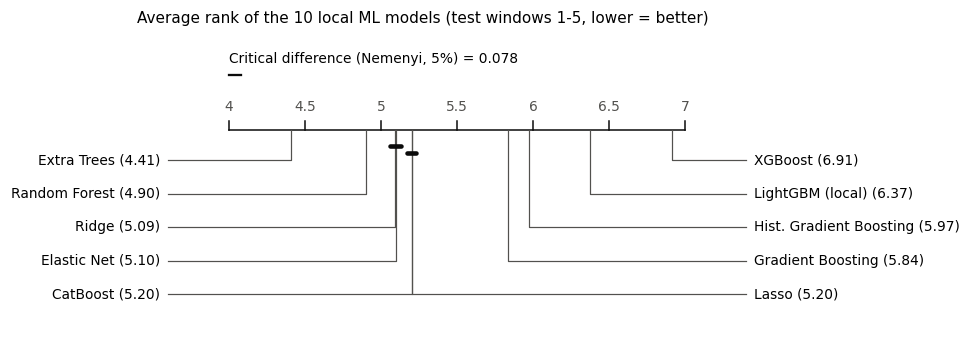

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_1_critical_difference.png
(Not plotted: oracle, best ML model per product = 0.7102; it would squeeze the scale.)


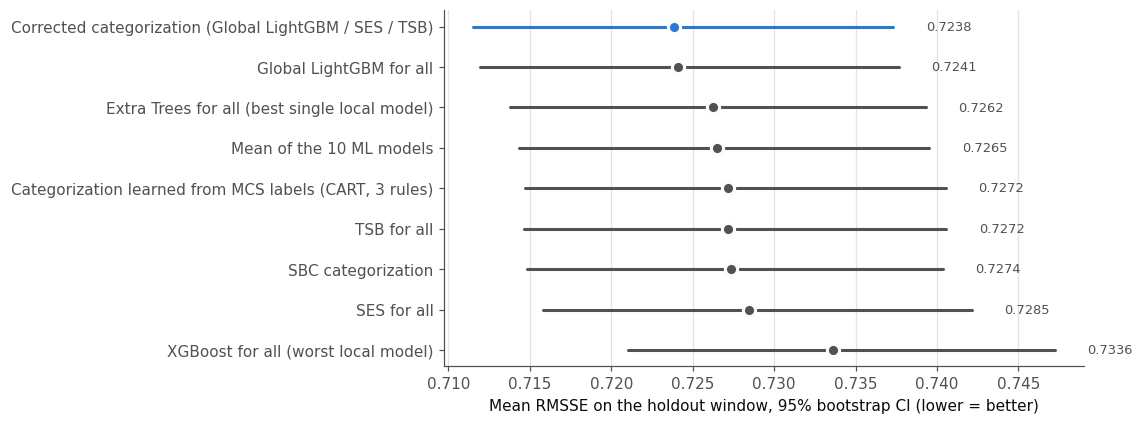

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_2_holdout_rmsse.png


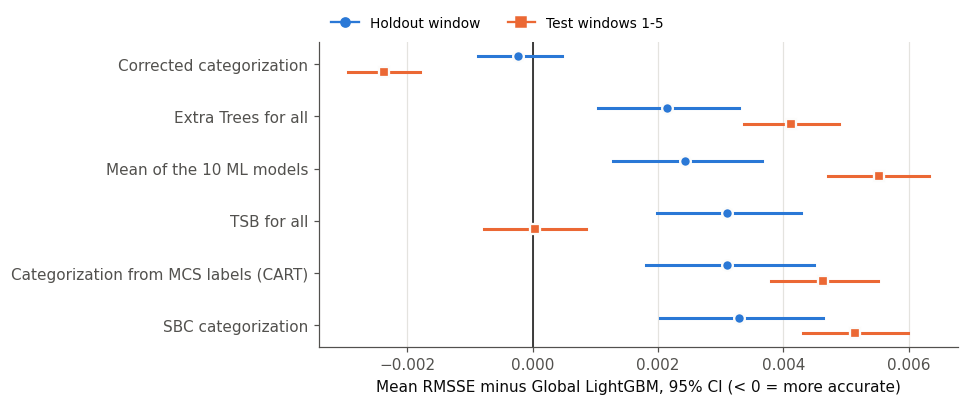

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_3_paired_vs_global.png


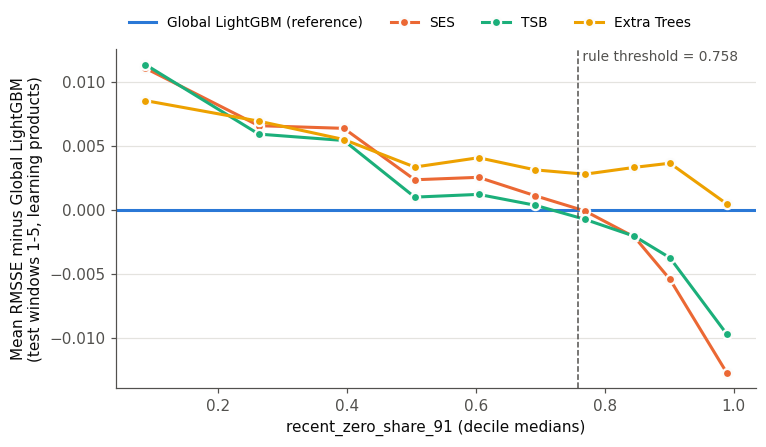

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_4_rule_mechanism.png


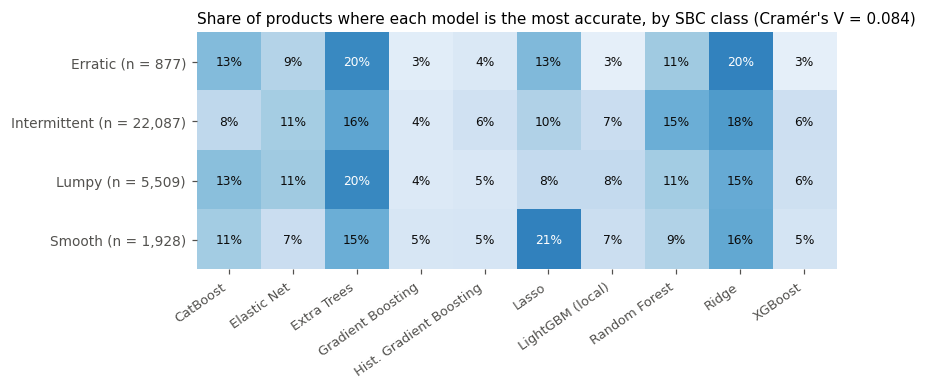

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_5_sbc_vs_best_model.png
✅ 5 figures saved in /content/drive/MyDrive/M5_Thesis/results/v2/final/figures


In [19]:
# Cell 14 — Figures for Chapter 4 (about 2-5 minutes). Needs Cells 1-9 and 12 in this session.
# Saved as PNG (300 dpi, for Word) and PDF (vector) in results/v2/final/figures/.
import matplotlib.pyplot as plt
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
INK, INK2, GRID, BLUE, ORANGE, AQUA, YELLOW = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.bbox': 'tight'})
NICE = {'EXTRA_TREES': 'Extra Trees', 'RANDOM_FOREST': 'Random Forest', 'RIDGE': 'Ridge', 'LASSO': 'Lasso', 'ELASTIC_NET': 'Elastic Net',
        'CATBOOST': 'CatBoost', 'LGBM': 'LightGBM (local)', 'XGBOOST': 'XGBoost', 'HGBR': 'Hist. Gradient Boosting',
        'GRADIENT_BOOST': 'Gradient Boosting', 'GLOBAL_LGBM': 'Global LightGBM', 'SES': 'SES', 'TSB': 'TSB', 'MEAN10': 'Mean of 10 ML models'}
nice = lambda m: NICE.get(m, m)
def save(fig, name):
    for ext in ('png', 'pdf'): fig.savefig(f'{FIG}/{name}.{ext}', dpi=300)
    plt.show(); print('saved', f'{FIG}/{name}.png')

# Figure 4.1 — Critical-difference diagram, 10 ML models (Friedman-Nemenyi, Cell 7)
rk = M10.rank(axis=1).mean().sort_values(); n = len(rk)
lo, hi = np.floor(rk.min() * 2) / 2, np.ceil(rk.max() * 2) / 2
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.set_xlim(lo - 0.6, hi + 0.6); ax.set_ylim(-(n + 1) // 2 * 0.55 - 0.1, 1.6); ax.axis('off')
ax.plot([lo, hi], [0, 0], color=INK, lw=1)
for t in np.arange(lo, hi + 1e-9, 0.5):
    ax.plot([t, t], [0, 0.15], color=INK, lw=1); ax.text(t, 0.3, f'{t:g}', ha='center', fontsize=9, color=INK2)
ax.plot([lo, lo + cd], [0.9, 0.9], color=INK, lw=1.5); ax.text(lo, 1.05, f'Critical difference (Nemenyi, 5%) = {cd:.3f}', ha='left', va='bottom', fontsize=9)
half = (n + 1) // 2
for i, (m, r) in enumerate(rk.items()):
    left = i < half; y = -(i if left else n - 1 - i) * 0.55 - 0.5
    xe = lo - 0.4 if left else hi + 0.4
    ax.plot([r, r, xe], [0, y, y], color=INK2, lw=0.8)
    ax.text(xe + (-0.05 if left else 0.05), y, f'{nice(m)} ({r:.2f})', ha='right' if left else 'left', va='center', fontsize=9)
groups, vals = [], rk.values                                  # maximal groups of models not significantly different
for i in range(n):
    j = max(k for k in range(i, n) if vals[k] - vals[i] <= cd)
    if j > i and not any(a <= i and j <= b for a, b in groups): groups.append((i, j))
for g, (i, j) in enumerate(groups):
    yy = -0.15 - 0.12 * (g + 1); ax.plot([vals[i] - 0.03, vals[j] + 0.03], [yy, yy], color=INK, lw=3, solid_capstyle='round')
ax.set_title('Average rank of the 10 local ML models (test windows 1-5, lower = better)', fontsize=10, loc='left')
save(fig, 'fig4_1_critical_difference')

# Figure 4.2 — Holdout mean RMSSE with 95% CI on the test products
EXT3 = 'RMSSE-rules, Extended pool, 3 rules'
show = [(EXT3, 'Corrected categorization (Global LightGBM / SES / TSB)'),
        ('GLOBAL_LGBM', 'Global LightGBM for all'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all (best single local model)"),
        ('MEAN10', 'Mean of the 10 ML models'), ('TSB', 'TSB for all'), ('SES', 'SES for all'),
        ('New categorization (CART, 3 rules)', 'Categorization learned from MCS labels (CART, 3 rules)'),
        ('SBC categorization', 'SBC categorization'), ('XGBOOST for all', 'XGBoost for all (worst local model)')]
st = []
for k, lab in show:
    s = summary(VALS[k][0], best_h); st.append((lab, s['Mean RMSSE'], s['CI 2.5%'], s['CI 97.5%'], k))
st = sorted(st, key=lambda z: -z[1])
fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
for i, (lab, m, a, b, k) in enumerate(st):
    c = BLUE if k == EXT3 else INK2
    ax.plot([a, b], [i, i], color=c, lw=2, solid_capstyle='round'); ax.plot(m, i, 'o', ms=8, color=c, mec='#fcfcfb', mew=2)
    ax.text(b + 0.002, i, f'{m:.4f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(range(len(st))); ax.set_yticklabels([z[0] for z in st]); ax.set_xlabel('Mean RMSSE on the holdout window, 95% bootstrap CI (lower = better)')
print(f'(Not plotted: oracle, best ML model per product = {np.average(best_h, weights=W):.4f}; it would squeeze the scale.)')
save(fig, 'fig4_2_holdout_rmsse')

# Figure 4.3 — Paired differences against Global LightGBM (holdout and test windows)
cmp = [(EXT3, 'Corrected categorization'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all"), ('MEAN10', 'Mean of the 10 ML models'),
       ('TSB', 'TSB for all'), ('New categorization (CART, 3 rules)', 'Categorization from MCS labels (CART)'), ('SBC categorization', 'SBC categorization')]
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True); ax.axvline(0, color=INK, lw=1)
for i, (k, lab) in enumerate(cmp[::-1]):
    for w, off, c, mk in [(0, 0.15, BLUE, 'o'), (1, -0.15, ORANGE, 's')]:
        p = paired(k, 'GLOBAL_LGBM', w)
        ax.plot([p['CI 2.5%'], p['CI 97.5%']], [i + off] * 2, color=c, lw=2); ax.plot(p['Difference in mean RMSSE'], i + off, mk, ms=7, color=c, mec='#fcfcfb', mew=1.5)
ax.set_yticks(range(len(cmp))); ax.set_yticklabels([z[1] for z in cmp[::-1]])
ax.plot([], [], 'o-', color=BLUE, label='Holdout window'); ax.plot([], [], 's-', color=ORANGE, label='Test windows 1-5')
ax.legend(frameon=False, fontsize=9, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_xlabel('Mean RMSSE minus Global LightGBM, 95% CI (< 0 = more accurate)')
save(fig, 'fig4_3_paired_vs_global')

# Figure 4.4 — Why the rule works: RMSSE minus Global LightGBM, by share of zero-sales days in the last 91 days
# (learning products, test windows 1-5; < 0 = the method is more accurate than Global LightGBM in that decile)
t3 = CORR[EXT3]; f0, thr = t3['splits'][0][1]; feat_name = SCALE_FREE[f0]
z = X.loc[TRAIN, feat_name]; bins = np.unique(np.quantile(z, np.linspace(0, 1, 11)))
grp = pd.cut(z, bins, include_lowest=True)
lines = [('SES', ORANGE), ('TSB', AQUA), (L90['best_single'], YELLOW)]
A5 = ALL5.reindex(d.index)[TRAIN]
tab = A5[[m for m, _ in lines]].sub(A5['GLOBAL_LGBM'], axis=0).groupby(grp.values, observed=True).mean()
mid = z.groupby(grp.values, observed=True).median().values
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axhline(0, color=BLUE, lw=2, label='Global LightGBM (reference)')
for m, c in lines:
    ax.plot(mid, tab[m].values, '-o', color=c, lw=2, ms=6, mec='#fcfcfb', mew=1.5, label=nice(m))
ax.axvline(thr, color=INK2, lw=1, ls='--'); ax.text(thr, ax.get_ylim()[1], f' rule threshold = {thr:.3f}', va='top', fontsize=9, color=INK2)
ax.set_xlabel(f'{feat_name} (decile medians)')
ax.set_ylabel('Mean RMSSE minus Global LightGBM\n(test windows 1-5, learning products)')
ax.legend(frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.02))
save(fig, 'fig4_4_rule_mechanism')

# Figure 4.5 — SBC class vs best ML model (row shares, all products; RQ2)
sh = ct.div(ct.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(7.5, 2.8)); im = ax.imshow(sh.values, cmap='Blues', vmin=0, vmax=max(0.3, sh.values.max()), aspect='auto')
ax.set_xticks(range(sh.shape[1])); ax.set_xticklabels([nice(c) for c in sh.columns], rotation=35, ha='right', fontsize=8.5)
ax.set_yticks(range(sh.shape[0])); ax.set_yticklabels([f'{c.title()} (n = {ct.loc[c].sum():,})' for c in sh.index], fontsize=9)
for i in range(sh.shape[0]):
    for j in range(sh.shape[1]):
        v = sh.values[i, j]; ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * im.get_clim()[1] else INK)
ax.spines[:].set_visible(False); ax.set_title(f"Share of products where each model is the most accurate, by SBC class (Cramér's V = {V:.3f})", fontsize=10, loc='left')
save(fig, 'fig4_5_sbc_vs_best_model')
print('✅ 5 figures saved in', FIG)

In [ ]:
import shutil, os, subprocess
SRC = '/content/drive/MyDrive/M5_Thesis/results/v2'
DST = '/content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02'
print(subprocess.run(['du', '-sh', SRC], capture_output=True, text=True).stdout)   # size of what is copied
if not os.path.exists(DST):
    shutil.copytree(SRC, DST)
n = lambda p: sum(len(f) for _, _, f in os.walk(p))
print(f'Files in v2: {n(SRC):,} | files in the frozen copy: {n(DST):,}')
print('✅ Frozen copy:', DST)

580M	/content/drive/MyDrive/M5_Thesis/results/v2

Files in v2: 489 | files in the frozen copy: 489
✅ Frozen copy: /content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02


In [ ]:
# Cell 15 — Audit additions (about 5-10 minutes). Needs Cells 1-9 and 12 in this session.
# Computes in Colab the numbers added to Chapters 3-4 during the audit, so that every number in the thesis
# comes from this notebook. Nothing is refitted except the corrected rules (fit_rules of Cell 12) on subsets.
from scipy import stats
AUD = {}
# a) RQ2: chi-square, Cramer's V, share of products on which each model is best, by SBC class (test windows, all products)
best10 = ALL5.loc[common, MODELS].idxmin(axis=1); sb = d.loc[common, 'sbc']; kp = sb.isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']).values
ct = pd.crosstab(sb[kp], best10[kp]); chi = stats.chi2_contingency(ct)
print(f"RQ2: chi2 = {chi[0]:.1f}, df = {chi[2]}, p = {chi[1]:.2e}, n = {ct.values.sum():,}, Cramer's V = {np.sqrt(chi[0] / (ct.values.sum() * (min(ct.shape) - 1))):.4f}")
AUD['RQ2 best-model shares'] = ct.div(ct.sum(1), axis=0).round(4)
print(AUD['RQ2 best-model shares'].to_string())
# b) RQ1 by SBC class: mean RMSSE (windows 1-5) of every method, all products with every method
AUD['RQ1 by class'] = ALL5.loc[common].groupby(d.loc[common, 'sbc']).mean().T.round(4)
print('Mean RMSSE by SBC class (windows 1-5):'); print(AUD['RQ1 by class'].to_string())
# c) products on which the zero forecast is best (18 methods): share with at least one all-zero test window
zbest = ALL5.loc[common].idxmin(axis=1) == 'ZERO'
az5 = set(AZ.loc[AZ.Window <= 5, 'SKU_ID'])
print(f"Zero forecast best on {zbest.mean():.1%} of products; of these, {np.mean([s in az5 for s in zbest[zbest].index]):.1%} have at least one all-zero test window")
# d) launches: first sale after day 1
Ysl = sales[day_cols].to_numpy(float)[:, :1745]
fs = pd.Series(np.where((Ysl > 0).any(1), (Ysl > 0).argmax(1) + 1, np.nan), index=sales.index).dropna()
print(f"Products whose first sale is after day 1: {(fs > 1).sum():,} of {len(fs):,} products with a sale before day 1,746 ({(fs > 1).mean():.1%}); median first-sale day {fs.median():.0f}; after day 365: {(fs > 365).sum():,}")
# e) MCS: products where the test was undefined and the tie rule was used
print('MCS status counts:', mcs['mcs_status'].value_counts().to_dict() if 'mcs_status' in mcs else 'column absent')
# f) Figure 4.4 values: mean RMSSE minus Global LightGBM by decile of recent_zero_share_91 (learning products, windows 1-5)
z = X.loc[TRAIN, 'recent_zero_share_91']; grp = pd.qcut(z, 10, duplicates='drop')
A5 = ALL5.reindex(d.index)[TRAIN]
dec = A5[['SES', 'TSB', L90['best_single']]].sub(A5['GLOBAL_LGBM'], axis=0).groupby(grp.values, observed=True).mean()
dec.insert(0, 'median share of zero days (last 91)', z.groupby(grp.values, observed=True).median().values); dec.insert(1, 'products', z.groupby(grp.values, observed=True).size().values)
AUD['Fig 4.4 values'] = dec.round(4).reset_index(drop=True); print(AUD['Fig 4.4 values'].to_string())
# g) oracle gap captured, exact (holdout, ten-model oracle)
og = {}
for nm in ['New categorization (CART, 3 rules)', 'New categorization (CART, 4 rules)', 'Selector (random forests, 18 characteristics)', 'SBC categorization']:
    bs_, nv, orc = np.average(VALS['Best single model (learned)'][0], weights=W), np.average(VALS[nm][0], weights=W), np.average(best_h, weights=W)
    og[nm] = round(100 * (bs_ - nv) / (bs_ - orc), 2)
print('Share of the oracle gap captured (%):', og)
# h) the 4-rule tree of the first design
print('First design, 4 rules:'); print(export_text(L90['t4'], feature_names=SCALE_FREE, decimals=3))
# i) corrected rule (extended pool, 3 rules) under checks 2-5 of the first design
EXT = POOLS['Extended pool']; rows = []
def unweighted(ch, mask):
    m = mask & ALLH.reindex(d.index).notna().all(1).values
    return np.mean(test_vals_any(ch, ALLH, m)), m.sum()
def test_vals_any(ch, table, m):
    sub = table.loc[d.index[m]]
    return sub.values[np.arange(m.sum()), [sub.columns.get_loc(c) for c in ch[m]]]
rule = CORR['RMSSE-rules, Extended pool, 3 rules']['choice']; glob_ = np.array(['GLOBAL_LGBM'] * len(d)); et = np.array([L90['best_single']] * len(d))
not_tuned = ~d.index.isin(tune_ids); zero_p = d.index.isin(AZ.SKU_ID.unique())
for lab, mask in [('Test products not used for tuning', TEST & not_tuned), ('Test products without all-zero windows', TEST & ~zero_p)]:
    m = mask & ev_mask; w = weights(m)
    v = {k: np.average(test_vals_any(ch, ALLH, m), weights=w) for k, ch in [('Corrected rule', rule), ('Global LightGBM', glob_), ('Best single ML model', et)]}
    rows.append({'Check': lab, **v, 'products': int(m.sum())})
for lab, src in [('Learn California -> score Texas + Wisconsin', (d.state == 'CA').values), ('Learn Foods -> score Hobbies + Household', (d.cat == 'FOODS').values)]:
    t = fit_rules(src, EXT, 3); tgt = ~src
    v = {k: unweighted(ch, tgt)[0] for k, ch in [('Corrected rule', t['choice']), ('Global LightGBM', glob_), ('Best single ML model', et)]}
    rows.append({'Check': lab, **v, 'products': int(unweighted(rule, tgt)[1]), 'Rules learned': describe(t)})
AUD['Corrected rule robustness'] = pd.DataFrame(rows)
print(AUD['Corrected rule robustness'].drop(columns='Rules learned', errors='ignore').round(4).to_string(index=False))
for r in rows:
    if 'Rules learned' in r: print(r['Check']); print(r['Rules learned'])
# k) version of the arch library (Model Confidence Set), not recorded in Cell 3 of the tuning notebook
try:
    import arch; print('arch version:', arch.__version__)
except Exception as e: print('arch not importable here:', e)
# j) learning products with a missing method value (penalised in fit_rules)
miss = ALL5.reindex(d.index)[TRAIN][EXT].isna().any(axis=1).sum()
print(f'Learning products with a missing value for a method of the extended pool: {miss}')
with pd.ExcelWriter(f'{OUT}/Audit_additions_v2.xlsx') as xw:
    for k, v in AUD.items(): v.to_excel(xw, sheet_name=k[:31])
print('✅ Saved', f'{OUT}/Audit_additions_v2.xlsx')

RQ2: chi2 = 638.6, df = 27, p = 2.61e-117, n = 30,401, Cramer's V = 0.0837
col_0         CATBOOST  ELASTIC_NET  EXTRA_TREES  GRADIENT_BOOST    HGBR   LASSO    LGBM  RANDOM_FOREST   RIDGE  XGBOOST
sbc                                                                                                                     
ERRATIC         0.1323       0.0924       0.1973          0.0319  0.0445  0.1345  0.0262         0.1106  0.2041   0.0262
INTERMITTENT    0.0813       0.1063       0.1609          0.0401  0.0587  0.0956  0.0683         0.1500  0.1752   0.0637
LUMPY           0.1274       0.1107       0.1989          0.0405  0.0456  0.0770  0.0768         0.1073  0.1543   0.0615
SMOOTH          0.1074       0.0685       0.1489          0.0488  0.0498  0.2059  0.0659         0.0949  0.1572   0.0529
Mean RMSSE by SBC class (windows 1-5):
sbc             ERRATIC  INTERMITTENT   LUMPY  NO_SALE  SHORT_HISTORY  SMOOTH
LGBM             0.6544        0.7037  0.6481   0.6995         0.7947  0.7296
XGBO

In [ ]:
# Cell 16 — Prophet check: run time and accuracy against Extra Trees and Ridge (about 10-15 minutes). Needs Cells 1-3.
# Why: Chapter 3 excludes Prophet. This cell measures, on the study's own data, (a) how long Prophet takes per
# product-window compared with the local models and (b) how accurate it is, so the exclusion rests on evidence.
# Design: 60 test products (15 per SBC class, seed 0), test window 1 (days 1,746-1,773), same training history
# (from the first sale on day 43 or later) and the same RMSSE as the main study. Prophet with weekly and yearly
# seasonality, default settings, forecasts truncated at zero, as for the local models.
#   Version A: one Prophet fit per window, forecasting the 28 days at once (cheapest possible use of Prophet).
#   Version B: Prophet refitted every day, forecasting one day ahead (the protocol of the study), on 5 products.
import time, json, logging, warnings
try:
    from prophet import Prophet
except ImportError:
    import subprocess; subprocess.run(['pip', 'install', '-q', 'prophet']); from prophet import Prophet
import prophet; logging.getLogger('cmdstanpy').disabled = True; logging.getLogger('prophet').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')
PARAMS = json.load(open(FILES['tuned settings']))
DATES = pd.date_range('2011-01-29', periods=N_DAYS, freq='D')          # day 1 of the M5 data = 29 January 2011
d0 = EVAL_STARTS[0]; a, b = window_rows(d0)

def prophet_fit_predict(y_hist_days, hist_dates, future_dates):
    m = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
    m.fit(pd.DataFrame({'ds': hist_dates, 'y': y_hist_days}))
    return np.clip(m.predict(pd.DataFrame({'ds': future_dates}))['yhat'].values, 0, None)

rng = np.random.default_rng(0)
pool = d[TEST & d['sbc'].isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']).values]
pick = np.concatenate([rng.choice(pool.index[pool['sbc'] == c], 15, replace=False) for c in ['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']])
rows = []
for sku in pick:
    X, y = build_features(sales.loc[sku, day_cols].to_numpy(float))
    if not window_ok(y, d0): continue
    f = first_sale_row(y[:a]); p = PARAMS[d.loc[sku, 'sbc']]
    r = {'SKU_ID': sku, 'sbc': d.loc[sku, 'sbc']}
    for m in ['EXTRA_TREES', 'RIDGE']:
        t0 = time.perf_counter(); yte, pred, ytr = fit_predict(m, p[m], X, y, d0, n_jobs=1)
        r[f'{m} seconds'] = time.perf_counter() - t0; r[f'{m} RMSSE'] = rmsse(yte, pred, ytr)
    tdates = DATES[MAX_LAG:]                                              # target row r = day r + 43
    t0 = time.perf_counter(); pred = prophet_fit_predict(y[f:a], tdates[f:a], tdates[a:b])
    r['PROPHET_A seconds'] = time.perf_counter() - t0; r['PROPHET_A RMSSE'] = rmsse(y[a:b], pred, y[f:a])
    rows.append(r)
P = pd.DataFrame(rows).set_index('SKU_ID')

# Version B on the first 5 products: 28 daily refits, each forecasting the next day with the actual sales up to the day before
rowsB = []
for sku in P.index[:5]:
    X, y = build_features(sales.loc[sku, day_cols].to_numpy(float)); f = first_sale_row(y[:a]); tdates = DATES[MAX_LAG:]
    t0 = time.perf_counter(); pred = np.array([prophet_fit_predict(y[f:a + h], tdates[f:a + h], tdates[a + h:a + h + 1])[0] for h in range(H)])
    rowsB.append({'SKU_ID': sku, 'PROPHET_B seconds': time.perf_counter() - t0, 'PROPHET_B RMSSE': rmsse(y[a:b], pred, y[f:a])})
PB = pd.DataFrame(rowsB).set_index('SKU_ID')

# Results
print(f'Prophet {prophet.__version__} | {len(P)} test products, test window 1 (days {d0:,}-{d0 + H - 1:,})')
sec = {k: P[f'{k} seconds'].mean() for k in ['EXTRA_TREES', 'RIDGE', 'PROPHET_A']}; sec['PROPHET_B'] = PB['PROPHET_B seconds'].mean()
print('Mean seconds per product-window (one core):', {k: round(v, 3) for k, v in sec.items()})
print(f"Prophet A / Extra Trees: {sec['PROPHET_A'] / sec['EXTRA_TREES']:.1f}x | Prophet A / Ridge: {sec['PROPHET_A'] / sec['RIDGE']:.1f}x")
print(f"Prophet B (study protocol) / Extra Trees: {sec['PROPHET_B'] / sec['EXTRA_TREES']:.1f}x | Prophet B / Ridge: {sec['PROPHET_B'] / sec['RIDGE']:.1f}x")
n_pw = len(d) * len(WINDOWS)
for k in ['PROPHET_A', 'PROPHET_B', 'EXTRA_TREES']:
    print(f'Estimated time for all {n_pw:,} product-windows, one core: {sec[k] * n_pw / 3600:,.1f} hours ({k})')
acc = P[[c for c in P.columns if c.endswith('RMSSE')]]
print('Mean RMSSE on the same product-window (lower is better):'); print(acc.mean().round(4).to_string())
print('By SBC class:'); print(acc.groupby(P['sbc']).mean().round(4).to_string())
diff = acc['PROPHET_A RMSSE'] - acc['EXTRA_TREES RMSSE']
print(f"Prophet A minus Extra Trees: mean {diff.mean():+.4f}, Prophet A better on {(diff < 0).mean():.0%} of the products")
print('Version B on 5 products:'); print(PB.join(acc[['PROPHET_A RMSSE', 'EXTRA_TREES RMSSE']]).round(4).to_string())
with pd.ExcelWriter(f'{OUT}/Prophet_check_v2.xlsx') as xw:
    P.to_excel(xw, sheet_name='Version A, 60 products'); PB.to_excel(xw, sheet_name='Version B, 5 products')
print('✅ Saved', f'{OUT}/Prophet_check_v2.xlsx')

Prophet 1.5.0 | 60 test products, test window 1 (days 1,746-1,773)
Mean seconds per product-window (one core): {'EXTRA_TREES': np.float64(0.391), 'RIDGE': np.float64(0.004), 'PROPHET_A': np.float64(0.379), 'PROPHET_B': np.float64(9.188)}
Prophet A / Extra Trees: 1.0x | Prophet A / Ridge: 103.5x
Prophet B (study protocol) / Extra Trees: 23.5x | Prophet B / Ridge: 2506.6x
Estimated time for all 182,844 product-windows, one core: 19.3 hours (PROPHET_A)
Estimated time for all 182,844 product-windows, one core: 466.7 hours (PROPHET_B)
Estimated time for all 182,844 product-windows, one core: 19.9 hours (EXTRA_TREES)
Mean RMSSE on the same product-window (lower is better):
EXTRA_TREES RMSSE    0.6492
RIDGE RMSSE          0.6531
PROPHET_A RMSSE      0.6942
By SBC class:
              EXTRA_TREES RMSSE  RIDGE RMSSE  PROPHET_A RMSSE
sbc                                                          
ERRATIC                  0.5898       0.5952           0.6272
INTERMITTENT             0.8522       0.

In [ ]:
import shutil
SRC = '/content/drive/MyDrive/M5_Thesis/results/v2/final'
DST = '/content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02/final'
for f in ['Audit_additions_v2.xlsx', 'Prophet_check_v2.xlsx']:
    shutil.copy2(f'{SRC}/{f}', f'{DST}/{f}')
    print('✅ copied', f)

✅ copied Audit_additions_v2.xlsx
✅ copied Prophet_check_v2.xlsx


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
print(sorted(os.listdir('/content/drive/MyDrive/M5_Thesis/data')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Intermittent Demand_Categorisation and Forecasting (2).xls', 'Intermittent demand forecasting (Croston SBA SMA SES) (1).xls', 'calendar.csv', 'sales_train_evaluation.csv', 'sales_train_validation.csv', 'sell_prices.csv']


In [ ]:
# Cell 17 — Blind test on a new window W7 (days 1,914-1,941), never seen in the project (about 40-60 minutes).
# Needs Cells 1-9 in this session (Cell 12 is NOT needed: the rule is refitted below with the same code, identical result).
# PRE-SPECIFIED BEFORE ANY RESULT (3 November 2026):
#   - The final rule (extended pool, 3 rules) is applied UNCHANGED: same characteristics, same exact thresholds,
#     same methods. Characteristics are recomputed on days 1-1,913, as a manager would do on day 1,913.
#   - Methods: the rule, Global LightGBM, Extra Trees (best single ML model), SES and TSB, all with the settings
#     already tuned (nothing is re-tuned). Same one-day-ahead protocol as W1-W6.
#   - Score: the 3,305 test products evaluable on W7, weighted to the population SBC shares, mean RMSSE with
#     95% bootstrap intervals (1,000 resamples) and paired differences (2,000 resamples), seed as in Cell 9.
#   - Questions: (1) rule minus Global LightGBM: does the tie hold? (2) rule minus Extra Trees: is the rule still better?
# The actual sales of days 1,914-1,941 are read from sales_train_evaluation.csv, only in this cell.
from joblib import Parallel, delayed
W7_START = 1914; W7_END = W7_START + H - 1                                   # days 1,914-1,941

# 1) Exact thresholds of the final rule: refit with the Cell 12 code (deterministic, same data, same result)
POOL_EXT = MODELS + ['GLOBAL_LGBM', 'TSB', 'SES', 'MEAN10']
QS = np.arange(1, 100); XV = X.values; ORDER = [np.argsort(XV[:, f], kind='stable') for f in range(XV.shape[1])]
def best_split(R, rows, min_leaf=MIN_LEAF):
    base = R * rows[:, None]; n_all = rows.sum(); best = (np.inf, None)
    for f in range(XV.shape[1]):
        o = ORDER[f]; xs = XV[o, f]; cs = np.cumsum(base[o], 0); cc = np.cumsum(rows[o])
        thr = np.unique(np.percentile(XV[rows, f], QS)); pos = np.searchsorted(xs, thr, side='right') - 1
        ok = pos >= 0; thr, pos = thr[ok], pos[ok]
        nl = cc[pos]; good = (nl >= min_leaf) & (n_all - nl >= min_leaf)
        if not good.any(): continue
        L = cs[pos[good]]; Rr = cs[-1] - L; cost = L.min(1) + Rr.min(1); k = cost.argmin()
        if cost[k] < best[0]: best = (cost[k], (f, thr[good][k]))
    return best
def fit_rules(mask, pool, leaves):
    R = np.nan_to_num(ALL5.reindex(d.index)[pool].values, nan=1e6)
    rows = mask.copy(); tree = {'pool': pool, 'splits': []}; leaf_of = np.zeros(len(d), int)
    c, s = best_split(R, rows)
    tree['splits'].append((0, s)); leaf_of = np.where(XV[:, s[0]] <= s[1], 0, 1)
    cands = []
    for side in (0, 1):
        sub = rows & (leaf_of == side); c, s2 = best_split(R, sub)
        if s2 is not None: cands.append((R[sub].sum(0).min() - c, side, s2))
    cands.sort(key=lambda z: -z[0])
    for gain, side, s2 in cands[:leaves - 2]:
        if gain <= 0: continue
        tree['splits'].append((side + 1, s2)); new_id = leaf_of.max() + 1
        leaf_of = np.where((leaf_of == side) & (XV[:, s2[0]] > s2[1]), new_id, leaf_of)
    tree['leaf_model'] = {l: pool[int(R[rows & (leaf_of == l)].sum(0).argmin())] for l in np.unique(leaf_of[rows])}
    tree['leaf_of'] = leaf_of
    return tree
RULE = fit_rules(TRAIN, POOL_EXT, 3)
for parent, (f, t) in RULE['splits']: print(f'split (parent {parent}): {SCALE_FREE[f]} <= {t!r}')
print('methods per leaf:', RULE['leaf_model'],
      '| shares of learning products:', {l: round(float((RULE['leaf_of'][TRAIN] == l).mean()), 3) for l in RULE['leaf_model']})
def apply_rule(tree, XV_new):
    (_, (f0, t0)) = tree['splits'][0]; leaf = np.where(XV_new[:, f0] <= t0, 0, 1)
    for parent, (f, t) in tree['splits'][1:]:
        new_id = max(leaf.max(), 1) + 1
        leaf = np.where((leaf == parent - 1) & (XV_new[:, f] > t), new_id, leaf)
    return np.array([tree['leaf_model'][l] for l in leaf])
assert (apply_rule(RULE, XV)[TRAIN] == np.array([RULE['leaf_model'][l] for l in RULE['leaf_of']])[TRAIN]).all(), 'rule replay differs'

# 2) Sales of days 1-1,941; check that days 1-1,913 are identical to the file used everywhere else
SE = pd.read_csv(f'{D}/data/sales_train_evaluation.csv').set_index('id')
SE.index = SE.index.str.replace('_evaluation', '_validation'); SE = SE.reindex(sales.index)
dcols7 = [f'd_{k}' for k in range(1, W7_END + 1)]; Y7 = SE[dcols7].to_numpy(np.float64)
assert np.array_equal(Y7[:, :N_DAYS], sales[day_cols].to_numpy(np.float64)), 'days 1-1,913 differ between the two files'
print(f'✅ sales_train_evaluation.csv: {Y7.shape[0]:,} products x {Y7.shape[1]:,} days; days 1-1,913 identical to sales_train_validation.csv')

# 3) Characteristics used by the rule, recomputed on days 1-1,913 (definitions of Appendix A)
used = {SCALE_FREE[f] for _, (f, _) in RULE['splits']}
assert used <= {'recent_zero_share_91', 'zero_share_active', 'zero_share_all'}, f'rule uses other characteristics: {used}'
Yc = Y7[:, :N_DAYS]; has = (Yc > 0).any(1); first = np.where(has, (Yc > 0).argmax(1), N_DAYS)
act = np.arange(N_DAYS)[None, :] >= first[:, None]
zsa = np.where(has, ((Yc == 0) & act).sum(1) / np.maximum(act.sum(1), 1), np.nan)
last91 = act & (np.arange(N_DAYS)[None, :] >= N_DAYS - 91)
r91 = np.where(has, ((Yc == 0) & last91).sum(1) / np.maximum(last91.sum(1), 1), np.nan)
X7 = X.copy()
X7['zero_share_active'] = pd.Series(zsa, index=sales.index).reindex(d.index).values
X7['recent_zero_share_91'] = pd.Series(r91, index=sales.index).reindex(d.index).values
X7['zero_share_all'] = pd.Series((Yc == 0).mean(1), index=sales.index).reindex(d.index).values
X7 = X7.fillna(X[TRAIN].median())
rule7 = apply_rule(RULE, X7.values); rule_old = apply_rule(RULE, XV)
print('Rule on day 1,913, share of test products per method:', pd.Series(rule7[TEST]).value_counts(normalize=True).round(3).to_dict(),
      f'| same method as with the day-1,745 characteristics: {(rule7 == rule_old)[TEST].mean():.1%}')

# 4) Window W7 for the classical methods and the global LightGBM, with the notebook's own functions
YR_bak, YFULL_bak, WIN_bak = YR, YFULL, list(WINDOWS)
try:
    YR = Y7[:, MAX_LAG:]; YFULL = Y7; WINDOWS = WIN_bak + [W7_START]
    SC[7] = scale_table(W7_START); f7, sc7, ok7 = SC[7]
    t0 = time.time(); CL7 = run_classical(7); print(f'classical methods on W7 — {(time.time() - t0) / 60:.1f} min')
    prods = np.flatnonzero(ok7); Xtr, ytr, Xte, yte, own = pooled_fast(W7_START, prods, sc7)
    gm = build_model('LGBM', GP['params']); gm.fit(Xtr, ytr); G7 = global_rmsse(gm, Xte, yte, own, sc7, prods)
    print(f'global LightGBM on W7: {len(prods):,} products, {len(ytr):,} training rows — {(time.time() - t0) / 60:.1f} min')
    del Xtr, ytr, Xte, yte, own
finally:
    YR, YFULL, WINDOWS = YR_bak, YFULL_bak, WIN_bak; SC.pop(7, None)

# 5) Extra Trees on the test products (tuned settings of the product's class, as in the evaluation notebook)
PARAMS = json.load(open(FILES['tuned settings']))
pc = d['sbc'].where(d['sbc'].isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']), 'INTERMITTENT')
test_ids = d.index[TEST]
def et_one(sku):
    i = POS[sku]; Xf, y = build_features(Y7[i])
    if not window_ok(y, W7_START): return sku, np.nan
    yte_, pred, ytr_ = fit_predict('EXTRA_TREES', PARAMS[pc[sku]]['EXTRA_TREES'], Xf, y, W7_START, n_jobs=1)
    return sku, rmsse(yte_, pred, ytr_)
t0 = time.time(); ET7 = pd.Series(dict(Parallel(n_jobs=-1)(delayed(et_one)(s) for s in test_ids)))
print(f'Extra Trees on W7: {ET7.notna().sum():,} test products — {(time.time() - t0) / 60:.1f} min')

# 6) Scores on the test products evaluable on W7
T7 = pd.DataFrame(index=d.index)
for k in ['SES', 'TSB']: T7[k] = CL7[CL7.Method == k].set_index('SKU_ID')['RMSSE'].reindex(d.index)
T7['GLOBAL_LGBM'] = pd.Series(G7.values, index=sales.index[G7.index]).reindex(d.index)
T7['EXTRA_TREES'] = ET7.reindex(d.index)
need = sorted(set(rule7[TEST]) | {'GLOBAL_LGBM', 'EXTRA_TREES', 'SES', 'TSB'})
assert set(need) <= set(T7.columns), f'rule chooses a method not computed on W7: {set(need) - set(T7.columns)}'
m7 = TEST & T7[need].notna().all(1).values; W7w = weights(m7); sub = T7[m7]
vals = {'Final rule (extended pool, 3 rules)': sub.values[np.arange(m7.sum()), [sub.columns.get_loc(c) for c in rule7[m7]]],
        'Global LightGBM for all': sub['GLOBAL_LGBM'].values, 'Extra Trees for all': sub['EXTRA_TREES'].values,
        'SES for all': sub['SES'].values, 'TSB for all': sub['TSB'].values}
def ci_mean(v, reps=1000):
    rng = np.random.default_rng(SEED); n = len(v)
    b = [np.average(v[i], weights=W7w[i]) for i in (rng.integers(0, n, n) for _ in range(reps))]
    return np.average(v, weights=W7w), np.percentile(b, 2.5), np.percentile(b, 97.5), np.median(v)
res = pd.DataFrame([dict(zip(['Method', 'Mean RMSSE', 'CI 2.5%', 'CI 97.5%', 'Median RMSSE'], (k, *ci_mean(v)))) for k, v in vals.items()])
def pair(a, b, reps=2000):
    x, y = vals[a], vals[b]; rng = np.random.default_rng(SEED); n = len(x)
    dd = [np.average(x[i] - y[i], weights=W7w[i]) for i in (rng.integers(0, n, n) for _ in range(reps))]
    return {'Comparison': f'{a}  minus  {b}', 'Difference': np.average(x - y, weights=W7w), 'CI 2.5%': np.percentile(dd, 2.5), 'CI 97.5%': np.percentile(dd, 97.5)}
R1 = 'Final rule (extended pool, 3 rules)'
prs = pd.DataFrame([pair(R1, 'Global LightGBM for all'), pair(R1, 'Extra Trees for all'),
                    pair('Global LightGBM for all', 'Extra Trees for all'), pair(R1, 'SES for all'), pair(R1, 'TSB for all')])
allzero7 = int((Y7[POS[d.index[m7]].values, W7_START - 1:W7_END] == 0).all(1).sum())
print(f'\nW7 (days {W7_START:,}-{W7_END:,}): {m7.sum():,} test products scored, weighted; {allzero7:,} of them sold nothing on W7')
print(res.round(4).sort_values('Mean RMSSE').to_string(index=False))
print('Paired differences (negative = the first method is more accurate):'); print(prs.round(4).to_string(index=False))
with pd.ExcelWriter(f'{OUT}/W7_blind_test_v2.xlsx') as xw:
    res.round(4).to_excel(xw, sheet_name='Results W7', index=False); prs.round(4).to_excel(xw, sheet_name='Paired differences W7', index=False)
    T7[m7].assign(rule=rule7[m7]).to_excel(xw, sheet_name='Per product')
print('✅ Saved', f'{OUT}/W7_blind_test_v2.xlsx')

split (parent 0): recent_zero_share_91 <= np.float64(0.7582417582417582)
split (parent 1): zero_share_active <= np.float64(0.8467853557085485)
methods per leaf: {np.int64(0): 'GLOBAL_LGBM', np.int64(1): 'SES', np.int64(2): 'TSB'} | shares of learning products: {np.int64(0): 0.639, np.int64(1): 0.348, np.int64(2): 0.013}
✅ sales_train_evaluation.csv: 30,490 products x 1,941 days; days 1-1,913 identical to sales_train_validation.csv
Rule on day 1,913, share of test products per method: {'GLOBAL_LGBM': 0.687, 'SES': 0.295, 'TSB': 0.018} | same method as with the day-1,745 characteristics: 82.9%
classical methods on W7 — 1.2 min
global LightGBM on W7: 30,490 products, 11,094,773 training rows — 7.1 min
Extra Trees on W7: 3,305 test products — 19.9 min

W7 (days 1,914-1,941): 3,305 test products scored, weighted; 77 of them sold nothing on W7
                             Method  Mean RMSSE  CI 2.5%  CI 97.5%  Median RMSSE
Final rule (extended pool, 3 rules)      0.7479   0.7363    0.7584   

In [ ]:
import shutil
shutil.copy2('/content/drive/MyDrive/M5_Thesis/results/v2/final/W7_blind_test_v2.xlsx',
             '/content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02/final/W7_blind_test_v2.xlsx')
print('✅ copied')

✅ copied


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Products per class (days 1-1,745): {'INTERMITTENT': 22087, 'LUMPY': 5509, 'SMOOTH': 1928, 'ERRATIC': 877} | total 30401


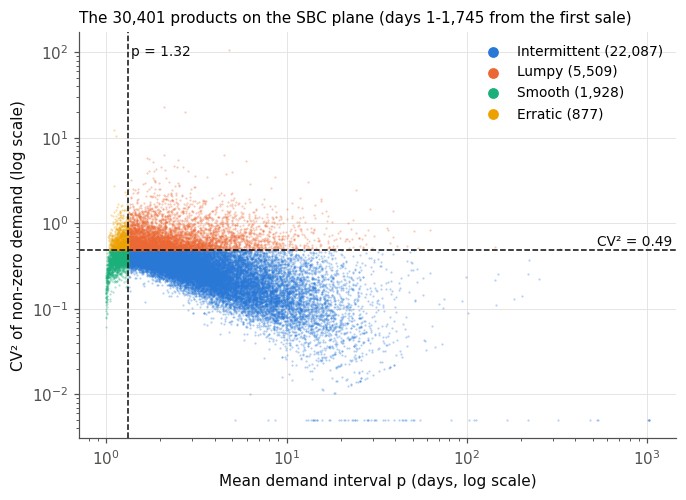

saved fig3_1_sbc_plane in ['/content/drive/MyDrive/M5_Thesis/results/v2/final/figures', '/content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02/final/figures']
60 products with CV² = 0 are drawn at CV² = 0.005
SMOOTH        FOODS_2_150_CA_2_validation      p = 1.18  CV² = 0.376  (class median p = 1.18, CV² = 0.376)
ERRATIC       FOODS_3_032_CA_3_validation      p = 1.21  CV² = 0.610  (class median p = 1.21, CV² = 0.613)
INTERMITTENT  HOUSEHOLD_2_084_TX_1_validation  p = 3.37  CV² = 0.290  (class median p = 3.37, CV² = 0.290)
LUMPY         FOODS_3_335_TX_2_validation      p = 2.12  CV² = 0.625  (class median p = 2.12, CV² = 0.622)


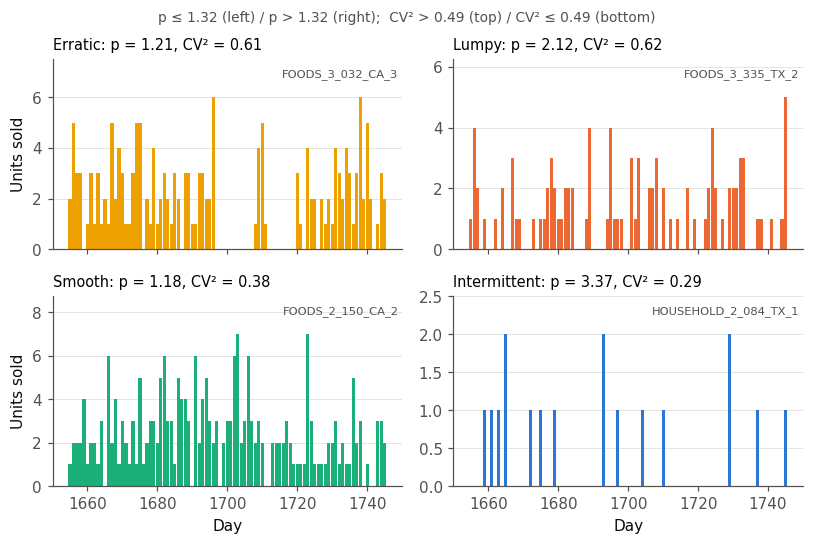

saved fig2_x_sbc_examples in ['/content/drive/MyDrive/M5_Thesis/results/v2/final/figures', '/content/drive/MyDrive/M5_Thesis/results/v2_FROZEN_2026-11-02/final/figures']
✅ 2 SBC figures saved in the results and frozen figure folders


In [ ]:
# Cell 18 — Two SBC figures (about 1-2 minutes). Standalone: needs only Google Drive.
# Figure 2.x (Chapter 2): the four SBC classes, each illustrated by one real M5 product (the most typical of its class).
# Figure 3.1 (Chapter 3): the 30,401 classified products on the SBC plane (days 1-1,745).
# Both are drawn from the frozen inputs (classes_cut1745.csv and sales_train_validation.csv); nothing is recomputed
# except the selection of the four example products, by a fixed rule stated below.
from google.colab import drive; drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
D = '/content/drive/MyDrive/M5_Thesis'; V2 = f'{D}/results/v2'
FIGS = [f'{V2}/final/figures', f'{D}/results/v2_FROZEN_2026-11-02/final/figures']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
COL = {'SMOOTH': '#1baf7a', 'ERRATIC': '#eda100', 'INTERMITTENT': '#2a78d6', 'LUMPY': '#eb6834'}
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.bbox': 'tight'})
def save(fig, name):
    for folder in FIGS:
        os.makedirs(folder, exist_ok=True)
        for ext in ('png', 'pdf'): fig.savefig(f'{folder}/{name}.{ext}', dpi=300)
    plt.show(); print('saved', name, 'in', FIGS)

cls = pd.read_csv(f'{V2}/classes_cut1745.csv').set_index('SKU_ID')
K = cls[cls['class_cut1745'].isin(COL)].copy()
P_CUT, C_CUT = 1.32, 0.49
counts = K['class_cut1745'].value_counts()
print('Products per class (days 1-1,745):', counts.to_dict(), '| total', len(K))

# Figure 3.1 — the SBC plane. CV2 = 0 (a single sale, or identical sizes) cannot be shown on a log axis: drawn at the floor.
FLOOR = 0.005; n0 = int((K['cv2_cut1745'] <= 0).sum())
fig, ax = plt.subplots(figsize=(7.0, 4.8))
for c in ['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']:
    s = K[K['class_cut1745'] == c]
    ax.scatter(s['p_cut1745'], s['cv2_cut1745'].clip(lower=FLOOR), s=2, alpha=0.35, color=COL[c], lw=0, rasterized=True,
               label=f"{c.title()} ({counts[c]:,})")
ax.set_xscale('log'); ax.set_yscale('log')
ax.axvline(P_CUT, color=INK, lw=1, ls='--'); ax.axhline(C_CUT, color=INK, lw=1, ls='--')
ax.text(P_CUT * 1.04, ax.get_ylim()[1] * 0.7, 'p = 1.32', fontsize=9, color=INK, va='top')
ax.text(ax.get_xlim()[1] * 0.95, C_CUT * 1.12, 'CV² = 0.49', fontsize=9, color=INK, ha='right')
ax.set_xlabel('Mean demand interval p (days, log scale)'); ax.set_ylabel('CV² of non-zero demand (log scale)')
ax.grid(True, which='major', color=GRID, lw=0.6); ax.set_axisbelow(True)
lg = ax.legend(frameon=False, fontsize=9, loc='upper right', markerscale=5)
for h in lg.legend_handles: h.set_alpha(1)
ax.set_title(f'The {len(K):,} products on the SBC plane (days 1-1,745 from the first sale)', fontsize=10, loc='left')
save(fig, 'fig3_1_sbc_plane')
print(f'{n0} products with CV² = 0 are drawn at CV² = {FLOOR}')

# Figure 2.x — one typical product per class: the product closest to its class median of log p and log CV2
# (products with CV2 = 0 excluded), shown over the last 91 days before the first test day (days 1,655-1,745).
sales = pd.read_csv(f'{D}/data/sales_train_validation.csv').set_index('id')
days = [f'd_{k}' for k in range(1655, 1746)]
pick = {}
for c in COL:
    s = K[(K['class_cut1745'] == c) & (K['cv2_cut1745'] > 0)]
    lp, lc = np.log(s['p_cut1745']), np.log(s['cv2_cut1745'])
    dist = (lp - lp.median()) ** 2 + (lc - lc.median()) ** 2
    pick[c] = dist.idxmin()
    print(f"{c:13s} {pick[c]:32s} p = {s.loc[pick[c], 'p_cut1745']:.2f}  CV² = {s.loc[pick[c], 'cv2_cut1745']:.3f}  "
          f"(class median p = {s['p_cut1745'].median():.2f}, CV² = {s['cv2_cut1745'].median():.3f})")
layout = [['ERRATIC', 'LUMPY'], ['SMOOTH', 'INTERMITTENT']]          # rows: CV2 above / below 0.49; columns: p below / above 1.32
fig, axes = plt.subplots(2, 2, figsize=(7.5, 4.8), sharex=True)
for i in range(2):
    for j in range(2):
        c = layout[i][j]; ax = axes[i, j]; y = sales.loc[pick[c], days].to_numpy(float)
        ax.bar(range(1655, 1746), y, width=0.9, color=COL[c])
        ax.set_title(f"{c.title()}: p = {K.loc[pick[c], 'p_cut1745']:.2f}, CV² = {K.loc[pick[c], 'cv2_cut1745']:.2f}", fontsize=9.5, loc='left')
        ax.text(0.99, 0.95, pick[c].replace('_validation', ''), transform=ax.transAxes, ha='right', va='top', fontsize=7.5, color=INK2)
        ax.set_ylim(0, max(1, y.max()) * 1.25); ax.grid(True, axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
        if j == 0: ax.set_ylabel('Units sold')
        if i == 1: ax.set_xlabel('Day')
fig.text(0.5, 1.0, 'p ≤ 1.32 (left) / p > 1.32 (right);  CV² > 0.49 (top) / CV² ≤ 0.49 (bottom)', ha='center', fontsize=9, color=INK2)
fig.tight_layout()
save(fig, 'fig2_x_sbc_examples')
print('✅ 2 SBC figures saved in the results and frozen figure folders')

In [ ]:
# Cell 19 — Where do the class changes of Table 3.4 come from? (about 2-3 minutes). Standalone: needs only Google Drive.
# Question 1: can the reference classification (days 1-1,913, from day 1) be reproduced with the SBC definition of
#             Section 3.3 (p = T/N, CV2 of non-zero demand with divisor N-1, cut-offs 1.32 / 0.49)?
# Question 2: of the products that change class, how many change because the history now starts at the first sale,
#             and how many because it now ends on day 1,745 instead of day 1,913?
from google.colab import drive; drive.mount('/content/drive')
import os, numpy as np, pandas as pd
D = '/content/drive/MyDrive/M5_Thesis'; V2 = f'{D}/results/v2'
OUTS = [f'{V2}/final', f'{D}/results/v2_FROZEN_2026-11-02/final']
CLASSES = ['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']

sales = pd.read_csv(f'{D}/data/sales_train_validation.csv').set_index('id')
day_cols = [c for c in sales.columns if c.startswith('d_')]; assert len(day_cols) == 1913
Y = sales[day_cols].to_numpy(float)
stored = pd.read_csv(f'{V2}/classes_cut1745.csv').set_index('SKU_ID').reindex(sales.index)
ref_file = pd.read_csv(f'{D}/results/demand_classification_results.csv').set_index('id')
print('Columns of the reference file:', list(ref_file.columns))

def sbc(y, from_first_sale, ddof=1, min_days=50):
    """Same rule as sbc_class (Section 3.3); from_first_sale=False starts the history on day 1, as the reference did."""
    nz = np.flatnonzero(y > 0)
    if len(nz) == 0: return 'NO_SALE', np.nan, np.nan
    if from_first_sale: y = y[nz[0]:]
    pos = y[y > 0]; p = len(y) / len(pos)
    if from_first_sale and len(y) < min_days: return 'SHORT_HISTORY', p, np.nan
    cv2 = pos.var(ddof=ddof) / pos.mean() ** 2 if len(pos) > 1 else 0.0
    return (('SMOOTH' if cv2 <= 0.49 else 'ERRATIC') if p <= 1.32 else ('INTERMITTENT' if cv2 <= 0.49 else 'LUMPY')), p, cv2

def classify(col, **kw):
    r = [sbc(y, **kw) for y in col]
    return pd.DataFrame(r, index=sales.index, columns=['cls', 'p', 'cv2'])

REF = stored['class_official_1913']
# Question 1: reproduce the reference
for ddof in (1, 0):
    R = classify(Y, from_first_sale=False, ddof=ddof)
    print(f"Recomputed reference (days 1-1,913 from day 1, CV2 divisor N-{ddof}): same class as the stored reference for "
          f"{(R['cls'] == REF).mean():.2%} of {len(REF):,} products")
    if ddof == 1: R1 = R
num = [c for c in ref_file.columns if ref_file[c].dtype.kind in 'fi']
for c in num:                                                               # pair each numeric reference column with p or CV2
    v = ref_file[c].reindex(sales.index); diffs = {}
    for k in ('p', 'cv2'):
        ok = v.notna() & R1[k].notna()
        if ok.sum(): diffs[k] = np.abs(v[ok] - R1[k][ok]).max()
    if diffs:
        k = min(diffs, key=diffs.get)
        print(f'  reference column {c!r} matches the recomputed {k}: largest absolute difference {diffs[k]:.6f}')
mism = R1['cls'] != REF
if mism.any(): print('Products where the recomputed and stored reference classes differ:', int(mism.sum()))

# Question 2: decompose reference -> final into a start effect and an end effect
S = classify(Y, from_first_sale=True)['cls']                                 # from the first sale, still ending on day 1,913
F = stored['class_cut1745']                                                  # final: first sale to day 1,745
assert (classify(Y[:, :1745], from_first_sale=True)['cls'] == F).all(), 'final classes not reproduced'
steps = {'Step 1 - start at the first sale (end day 1,913)': (REF, S), 'Step 2 - end on day 1,745 (from the first sale)': (S, F),
         'Both steps - reference to final (Table 3.4)': (REF, F)}
SHEET = {k: n for k, n in zip(steps, ['Step 1 start', 'Step 2 end', 'Both steps'])}
xl = {}
for name, (a, b) in steps.items():
    ct = pd.crosstab(a.rename('from'), b.rename('to'))
    xl[SHEET[name]] = ct
    print(f'\n{name}: {int((a != b).sum()):,} products change class'); print(ct.to_string())
for (x, y_), lab in [(('INTERMITTENT', 'LUMPY'), 'intermittent -> lumpy'), (('LUMPY', 'INTERMITTENT'), 'lumpy -> intermittent'),
                     (('INTERMITTENT', 'SMOOTH'), 'intermittent -> smooth'), (('LUMPY', 'ERRATIC'), 'lumpy -> erratic')]:
    moved = (REF == x) & (F == y_)
    print(f"{lab}: {int(moved.sum())} products; of these, {int((moved & (S == y_)).sum())} already changed at step 1 (start), "
          f"{int((moved & (S == x)).sum())} only at step 2 (end)")
for folder in OUTS:
    with pd.ExcelWriter(f'{folder}/Class_moves_decomposition_v2.xlsx') as xw:
        for k, v in xl.items(): v.to_excel(xw, sheet_name=k)
print('✅ Saved Class_moves_decomposition_v2.xlsx in the results and frozen folders')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Columns of the reference file: ['demand_category', 'MDI', 'CV2']
Recomputed reference (days 1-1,913 from day 1, CV2 divisor N-1): same class as the stored reference for 99.84% of 30,490 products
Recomputed reference (days 1-1,913 from day 1, CV2 divisor N-0): same class as the stored reference for 100.00% of 30,490 products
  reference column 'MDI' matches the recomputed p: largest absolute difference 0.000050
  reference column 'CV2' matches the recomputed cv2: largest absolute difference 0.275845
Products where the recomputed and stored reference classes differ: 49

Step 1 - start at the first sale (end day 1,913): 1,326 products change class
to            ERRATIC  INTERMITTENT  LUMPY  SMOOTH
from                                              
ERRATIC           497             0      0       0
INTERMITTENT        0         22138     48     916
LUMPY         

In [ ]:
# Cell 20 — Check of the Python code against the supervisor's reference spreadsheet (a few seconds). Standalone: needs only Drive.
# Spreadsheet: 'Intermittent Demand_Categorisation and Forecasting (2).xls' (M5_Thesis/data), sheets 'Croston' and 'Categorization'.
# The demand series is read from column B of each sheet (periods 1-72), so Python uses exactly the series the spreadsheet used.
# Forecasting part: alpha = 0.05; initial values from periods 1-12; forecasts and errors over periods 13-72 (as the spreadsheet).
#   Updating equations = those of run_classical (Cell 4 of the final notebook): SES level, Croston size Z and interval P
#   (interval = days since the last demand), SBA = (1 - alpha/2) Z/P; plus the 12-period moving average.
#   Bias = mean of (demand - forecast), MSE = mean of (demand - forecast)^2, as in the spreadsheet.
# Categorization part: sbc_class of Section 3.3 (history from the first sale, CV2 with divisor N-1).
import os, sys, subprocess, numpy as np, pandas as pd
try: import xlrd
except ImportError: subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'xlrd']); import xlrd
try:
    from google.colab import drive; drive.mount('/content/drive'); D = '/content/drive/MyDrive/M5_Thesis'
    OUTS = [f'{D}/results/v2/final', f'{D}/results/v2_FROZEN_2026-11-02/final']
except ImportError:                                  # local test outside Colab
    D = os.environ.get('M5_DIR', '.'); OUTS = [D]
XLS = f'{D}/data/Intermittent Demand_Categorisation and Forecasting (2).xls'
book = xlrd.open_workbook(XLS); cro = book.sheet_by_name('Croston'); cat = book.sheet_by_name('Categorization')
def _rc(cell):                                       # 'M3' -> (row, col), 0-based
    col = ''.join(ch for ch in cell if ch.isalpha()); row = int(''.join(ch for ch in cell if ch.isdigit()))
    c = 0
    for ch in col: c = c * 26 + ord(ch) - 64
    return row - 1, c - 1
get = lambda sh, cell: sh.cell_value(*_rc(cell))

# ---------- Part 1: forecasting (sheet 'Croston') ----------
y = np.array([cro.cell_value(r, 1) for r in range(15, 87)], float)          # B16:B87 = periods 1-72
alpha = float(get(cro, 'C3')); INIT = 12; T = len(y); assert T == 72 and alpha == 0.05
sizes0 = y[:INIT][y[:INIT] > 0]
M = np.zeros(T); ints0 = []                                                # spreadsheet counter 'time since last demand'
for t in range(T):
    M[t] = 1 if (t == 0 or y[t] > 0) else M[t - 1] + 1
    if t < INIT and y[t] > 0 and t > 0: ints0.append(M[t - 1])
L = y[:INIT].mean(); Z = sizes0.mean(); P = np.mean(ints0); Q = M[INIT - 1]   # initial values (periods 1-12)
fc = {'Croston': [], 'SBA': [], 'SES': [], 'MA12': []}
for t in range(INIT, T):
    fc['SES'].append(L); fc['Croston'].append(Z / P); fc['SBA'].append((1 - alpha / 2) * Z / P)
    fc['MA12'].append(y[t - 12:t].mean())
    # same updating equations as run_classical (Cell 4)
    dem = y[t] > 0
    L = L + alpha * (y[t] - L)
    if dem: Z = Z + alpha * (y[t] - Z); P = P + alpha * (Q - P)
    Q = 1 if dem else Q + 1
act = y[INIT:]
ref = {'Croston': ('M3', 'N3'), 'SES': ('M4', 'N4'), 'SBA': ('M5', 'N5'), 'MA12': ('M6', 'N6')}
rows = []
for k in ['Croston', 'SBA', 'SES', 'MA12']:
    e = act - np.array(fc[k]); b_py, m_py = e.mean(), (e ** 2).mean()
    b_xl, m_xl = float(get(cro, ref[k][0])), float(get(cro, ref[k][1]))
    rows.append({'Item': k, 'Spreadsheet bias': b_xl, 'Python bias': b_py, 'Spreadsheet MSE': m_xl, 'Python MSE': m_py,
                 'Largest abs. difference': max(abs(b_py - b_xl), abs(m_py - m_xl))})   # full precision, not rounded
F1 = pd.DataFrame(rows)
# period-by-period check of the forecast columns (spreadsheet columns C, G, P, V = MA, SES, Croston, SBA; rows 28-87 = periods 13-72)
colx = {'MA12': 2, 'SES': 6, 'Croston': 15, 'SBA': 21}
per = {k: np.abs(np.array([cro.cell_value(r, c) for r in range(27, 87)], float) - np.array(fc[k])).max() for k, c in colx.items()}

# ---------- Part 2: categorization (sheet 'Categorization') ----------
yc = np.array([cat.cell_value(r, 1) for r in range(13, 85)], float)        # B14:B85 = periods 1-72
def sbc_class(series_until_cut):                                           # identical to Section 3.3 / pipeline_v2.py
    y_ = np.asarray(series_until_cut, float); nz = np.flatnonzero(y_ > 0)
    if len(nz) == 0: return 'NO_SALE', np.nan, np.nan
    y_ = y_[nz[0]:]; pos = y_[y_ > 0]; p = len(y_) / len(pos)
    if len(y_) < 50: return 'SHORT_HISTORY', p, np.nan
    cv2 = pos.var(ddof=1) / pos.mean() ** 2 if len(pos) > 1 else 0.0
    return (('SMOOTH' if cv2 <= 0.49 else 'ERRATIC') if p <= 1.32 else ('INTERMITTENT' if cv2 <= 0.49 else 'LUMPY')), p, cv2
cls, p, cv2 = sbc_class(yc); pos = yc[np.flatnonzero(yc > 0)[0]:]; pos = pos[pos > 0]
xl_cls = 'LUMPY' if 'lumpy' in str(get(cat, 'I10')).lower() else str(get(cat, 'I10'))
F2 = pd.DataFrame([
    {'Item': 'Mean demand interval p', 'Spreadsheet': float(get(cat, 'J4')), 'Python': p},
    {'Item': 'Mean demand size', 'Spreadsheet': float(get(cat, 'J5')), 'Python': pos.mean()},
    {'Item': 'Demand size variance', 'Spreadsheet': float(get(cat, 'J6')), 'Python': pos.var(ddof=1)},
    {'Item': 'CV2 of demand size', 'Spreadsheet': float(get(cat, 'J7')), 'Python': cv2},
    {'Item': 'SBC class', 'Spreadsheet': xl_cls, 'Python': cls}])

pd.set_option('display.width', 200)
print(f'Series: column B of the sheets ({T} periods, {int((y > 0).sum())} with demand); alpha = {alpha}; errors over periods {INIT + 1}-{T}')
print('\nTable A — Forecasting: bias and MSE'); print(F1.to_string(index=False, float_format=lambda x: f'{x:.6f}' if abs(x) > 1e-4 else f'{x:.1e}'))
print('\nLargest period-by-period difference between the spreadsheet forecasts and the Python forecasts:',
      {k: f'{v_:.1e}' for k, v_ in per.items()})
print('\nTable B — Categorization'); print(F2.to_string(index=False))
ok1 = (F1['Largest abs. difference'] < 1e-12).all(); ok2 = all(abs(float(a) - float(b)) < 1e-12 for a, b in zip(F2.Spreadsheet[:4], F2.Python[:4])) and F2.Python[4] == F2.Spreadsheet[4]
print('\nForecasting identical (difference < 1e-12):', ok1, '| Categorization identical:', ok2)
for folder in OUTS:
    os.makedirs(folder, exist_ok=True)
    with pd.ExcelWriter(f'{folder}/Spreadsheet_check_v2.xlsx') as xw:
        F1.to_excel(xw, sheet_name='Forecasting', index=False); F2.to_excel(xw, sheet_name='Categorization', index=False)
        pd.DataFrame({'Method': list(per), 'Largest period difference': list(per.values())}).to_excel(xw, sheet_name='Per period', index=False)
print('✅ Saved Spreadsheet_check_v2.xlsx in', OUTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Series: column B of the sheets (72 periods, 26 with demand); alpha = 0.05; errors over periods 13-72

Table A — Forecasting: bias and MSE
   Item  Spreadsheet bias  Python bias  Spreadsheet MSE  Python MSE  Largest abs. difference
Croston         -0.113384    -0.113384         2.051731    2.051731                  8.9e-16
    SBA         -0.092633    -0.092633         2.047365    2.047365                  1.3e-15
    SES         -0.075844    -0.075844         2.105041    2.105041                  5.3e-16
   MA12         -0.054167    -0.054167         2.337384    2.337384                  1.3e-15

Largest period-by-period difference between the spreadsheet forecasts and the Python forecasts: {'MA12': '0.0e+00', 'SES': '6.7e-16', 'Croston': '2.2e-16', 'SBA': '3.3e-16'}

Table B — Categorization
                  Item Spreadsheet    Python
Mean demand interval p

In [ ]:
# Cell 22 — Global LightGBM: effect of truncating the forecasts at zero (about 1-2 hours).
# Run in the FINAL notebook after Cells 1, 2 and 3 (setup, pipeline definitions, data and RMSSE scales).
# The local models' forecasts are truncated at zero; the global LightGBM's were not. Truncation can only lower the
# squared error, since sales are never negative. This cell refits the global model of every window with the SAME saved
# settings (global_lgbm_params.json), computes its RMSSE with and without truncation from the same forecasts, checks
# that the untruncated RMSSE reproduces the saved results, and reports the share of negative forecasts and the change.
import os, json, time, numpy as np, pandas as pd
GL_DIR = f'{OUT}/global_lgbm'; CL_DIR = f'{OUT}/global_lgbm_clip'; os.makedirs(CL_DIR, exist_ok=True)
GP = json.load(open(f'{GL_DIR}/global_lgbm_params.json'))
YFULL = sales[day_cols].to_numpy(float)
def pooled_rows(start_day, prods, scale, train_days=365):           # identical to pooled_fast (Cell 5)
    a, b = window_rows(start_day); Xtr, ytr, Xte, yte, owner = [], [], [], [], []
    for i in prods:
        X, y = build_features(YFULL[i]); f = first_sale_row(y[:a]); s = np.sqrt(scale[i]); lo = max(f, a - train_days)
        Xtr.append(X[lo:a] / s); ytr.append(y[lo:a] / s); Xte.append(X[a:b] / s); yte.append(y[a:b]); owner.append(np.full(b - a, i))
    return (np.vstack(Xtr).astype(np.float32), np.concatenate(ytr).astype(np.float32),
            np.vstack(Xte).astype(np.float32), np.concatenate(yte), np.concatenate(owner))
def rmsse_by_product(yte, pred, owner, scale):
    df = pd.DataFrame({'o': owner, 'e2': (yte - pred) ** 2}); mse = df.groupby('o', sort=False)['e2'].mean()
    return pd.Series(np.sqrt(mse.values / scale[mse.index.values]), index=mse.index.values)
rows = []
for w, sd in enumerate(WINDOWS, 1):
    out = f'{CL_DIR}/window_{w}.csv'
    if os.path.exists(out): print(f'window {w}: already done'); continue
    t0 = time.time(); prods = np.flatnonzero(SC[w][2])
    Xtr, ytr, Xte, yte, own = pooled_rows(sd, prods, SC[w][1])
    m = build_model('LGBM', GP['params']); m.fit(Xtr, ytr)
    pred = m.predict(Xte) * np.sqrt(SC[w][1][own])
    r_raw = rmsse_by_product(yte, pred, own, SC[w][1]); r_clip = rmsse_by_product(yte, np.clip(pred, 0, None), own, SC[w][1])
    pd.DataFrame({'SKU_ID': sales.index[r_raw.index], 'Window': w, 'RMSSE_raw': r_raw.values, 'RMSSE_clip': r_clip.reindex(r_raw.index).values,
                  'neg_share': pd.Series(pred < 0).groupby(own).mean().reindex(r_raw.index).values}).to_csv(out, index=False)
    print(f'window {w}: {len(prods):,} products, negative forecasts {np.mean(pred < 0):.2%} — {(time.time() - t0) / 60:.1f} min')
G = pd.concat([pd.read_csv(f'{CL_DIR}/window_{w}.csv') for w in range(1, 7)])
OLD = pd.concat([pd.read_csv(f'{GL_DIR}/window_{w}.csv') for w in range(1, 7)]).rename(columns={'RMSSE': 'RMSSE_saved'})
G = G.merge(OLD[['SKU_ID', 'Window', 'RMSSE_saved']], on=['SKU_ID', 'Window'], how='left')
print(f"\nReproduction of the saved results (untruncated): largest absolute difference {np.nanmax(np.abs(G.RMSSE_raw - G.RMSSE_saved)):.2e}")
print(f"Share of negative forecasts (mean over product-windows): {G.neg_share.mean():.3%}")
print(f"Product-windows where truncation changes the RMSSE: {(G.RMSSE_raw - G.RMSSE_clip > 1e-12).mean():.2%}")
# Means as in the thesis: test windows 1-5 averaged per product; holdout window 6; all products, then the 3,305 test products weighted
T5 = G[G.Window <= 5].groupby('SKU_ID')[['RMSSE_raw', 'RMSSE_clip']].mean(); T6 = G[G.Window == 6].set_index('SKU_ID')[['RMSSE_raw', 'RMSSE_clip']]
summ = []
for name, T in [('Test windows 1-5', T5), ('Holdout W6', T6)]:
    allp = T.reindex(d.index).dropna()
    tm = TEST & d.index.isin(allp.index); Wt = weights(tm); tp = T.reindex(d.index[tm])
    summ.append({'Set': name, 'All products: mean untruncated': allp.RMSSE_raw.mean(), 'All products: mean truncated': allp.RMSSE_clip.mean(),
                 'Test products (weighted): mean untruncated': np.average(tp.RMSSE_raw, weights=Wt),
                 'Test products (weighted): mean truncated': np.average(tp.RMSSE_clip, weights=Wt)})
S = pd.DataFrame(summ); S['Change, test products'] = S['Test products (weighted): mean truncated'] - S['Test products (weighted): mean untruncated']
pd.set_option('display.width', 250); print(S.round(5).to_string(index=False))
for folder in [OUT, f'{D}/results/v2_FROZEN_2026-11-02/final']:
    with pd.ExcelWriter(f'{folder}/Global_truncation_check_v2.xlsx') as xw:
        S.to_excel(xw, sheet_name='Summary', index=False); G.to_excel(xw, sheet_name='Per product-window', index=False)
print('✅ Saved Global_truncation_check_v2.xlsx in the results and frozen folders')

window 1: 30,400 products, negative forecasts 0.00% — 6.1 min
window 2: 30,431 products, negative forecasts 0.00% — 5.6 min
window 3: 30,462 products, negative forecasts 0.00% — 5.9 min
window 4: 30,466 products, negative forecasts 0.00% — 5.8 min
window 5: 30,474 products, negative forecasts 0.00% — 5.8 min
window 6: 30,482 products, negative forecasts 0.00% — 5.9 min

Reproduction of the saved results (untruncated): largest absolute difference 8.88e-16
Share of negative forecasts (mean over product-windows): 0.000%
Product-windows where truncation changes the RMSSE: 0.01%
             Set  All products: mean untruncated  All products: mean truncated  Test products (weighted): mean untruncated  Test products (weighted): mean truncated  Change, test products
Test windows 1-5                         0.68258                       0.68258                                     0.68606                                   0.68606                   -0.0
      Holdout W6                         0.

In [ ]:
# Cell 23 — Checks requested in the review of Chapter 4 (about 10-20 minutes).
# Needs Cells 1-9, 12 and 13 in this session (Cell 13 is fast: its result file already exists).
# Nothing is refitted except the transferred rules of check 4-5 (same fit_rules as Cell 12, deterministic).
# Prints everything and saves results/v2/final/Review_checks_v2.xlsx.
OUTX = {}
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
EXT3 = 'RMSSE-rules, Extended pool, 3 rules'; BEST = 'Best single model (learned)'; NEW = 'New categorization (CART, 3 rules)'

# ---------------------------------------------------------------------------------------------------------------
# A) Check 7 (Section 4.4.2): class from the first sale to day 1,745 against the class from the first sale to day 1,913,
#    with the same definition (sbc_class of Cell 2). Text: 29,360 of 30,401 products (96.58%).
Yall = sales[day_cols].to_numpy(np.float64)
c1745 = pd.Series([sbc_class(y[:1745])[0] for y in Yall], index=sales.index)
c1913 = pd.Series([sbc_class(y)[0] for y in Yall], index=sales.index)
stored = pd.read_csv(FILES['classes']).set_index('SKU_ID')['class_cut1745'].reindex(sales.index)
assert (c1745 == stored).all(), 'day-1,745 classes not reproduced'
four = c1745.isin(['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC'])
same = (c1745[four] == c1913[four])
print(f'A) Check 7: same class on days 1,745 and 1,913 for {same.sum():,} of {four.sum():,} products ({same.mean():.2%})')
OUTX['A check 7'] = pd.crosstab(c1745[four], c1913[four])
print(OUTX['A check 7'].to_string())

# ---------------------------------------------------------------------------------------------------------------
# B) Checks 3, 4, 5 of the final rule (Section 4.7.2): products scored in check 3, and the rules learned on
#    California and on Foods with their exact thresholds and shares among the products they were learned on.
zero_p = d.index.isin(AZ.SKU_ID.unique())
m3 = TEST & ~zero_p & ev_mask
print(f'\nB) Check 3: test products without any all-zero window, scored: {m3.sum():,}')
EXT = POOLS['Extended pool']
for lab, src in [('Learned on California', (d.state == 'CA').values), ('Learned on Foods', (d.cat == 'FOODS').values)]:
    t = fit_rules(src, EXT, 3)
    print(f'\n{lab}: splits (parent, characteristic, threshold):')
    for parent, (f, thr) in t['splits']:
        print(f'   parent {parent}: {SCALE_FREE[f]} <= {thr:.4f}')
    sh = pd.Series(t['leaf_of'][src]).value_counts(normalize=True).sort_index()
    for l, s in sh.items():
        print(f'   leaf {l} -> {t["leaf_model"][l]:12s} {s:.1%} of the products it was learned on')

# ---------------------------------------------------------------------------------------------------------------
# C) Exact (unrounded) paired intervals whose rounded bound is 0.0000 (Sections 4.6.1 and 4.7.4)
def paired_exact(a, b, which=0, reps=2000):
    x, y = VALS[a][which], VALS[b][which]; rng = np.random.default_rng(SEED); n = len(x)
    dd = [np.average(x[i] - y[i], weights=W[i]) for i in (rng.integers(0, n, n) for _ in range(reps))]
    return np.average(x - y, weights=W), np.percentile(dd, 2.5), np.percentile(dd, 97.5)
print('\nC) Exact paired intervals (8 decimals):')
for a, b, w in [('RMSSE-rules, Extended pool (alpha 0.01-0.30), 3 rules', 'GLOBAL_LGBM', 0),
                ('RMSSE-rules, 10 ML models, 3 rules', BEST, 1)]:
    m_, lo, hi = paired_exact(a, b, w)
    print(f'   {a} minus {b} ({["holdout", "test windows"][w]}): {m_:.8f} [{lo:.8f}, {hi:.8f}]'
          f' -> {"significant" if (lo > 0 or hi < 0) else "tie (interval contains zero)"}')

# ---------------------------------------------------------------------------------------------------------------
# D) Table 4.6: holdout mean RMSSE of each first-design rule on its test products, with the rule's model and with
#    Extra Trees for all on the same products (weighted)
leaf = L90['t3'].apply(X); lev = leaf[ev_mask]
rows = []
for l in np.unique(leaf):
    k = lev == l
    if not k.any(): continue
    rows.append({'Rule model': choices[NEW][leaf == l][0], 'Share of the 30,474 products': (leaf == l).mean(),
                 'Test products': int(k.sum()),
                 'Holdout, rule model': np.average(VALS[NEW][0][k], weights=W[k]),
                 'Holdout, Extra Trees on the same products': np.average(VALS[BEST][0][k], weights=W[k])})
OUTX['D Table 4.6'] = pd.DataFrame(rows).round(4)
print('\nD) Table 4.6 with the new column:'); print(OUTX['D Table 4.6'].to_string(index=False))

# ---------------------------------------------------------------------------------------------------------------
# E) Item-level (cluster) bootstrap: resample the 3,049 items, all stores of an item together (limitation 6, 4.8.4)
item = pd.Series(d.index.str.rsplit('_', n=3).str[0], index=d.index)
def cluster_paired(x, y, w, items, reps=2000):
    codes, uniq = pd.factorize(items); groups = [np.flatnonzero(codes == g) for g in range(len(uniq))]
    rng = np.random.default_rng(SEED); dd = []
    for _ in range(reps):
        pick = rng.integers(0, len(groups), len(groups)); i = np.concatenate([groups[g] for g in pick])
        dd.append(np.average(x[i] - y[i], weights=w[i]))
    return np.percentile(dd, 2.5), np.percentile(dd, 97.5)
items_ev = item[d.index[ev_mask]].values
pairs = [(NEW, BEST), ('New categorization (CART, 4 rules)', BEST), ('Selector (random forests, 18 characteristics)', BEST),
         ('SBC categorization', BEST), (NEW, 'GLOBAL_LGBM'), (NEW, 'SBC categorization'), (NEW, 'MEAN10'), (NEW, 'TSB'),
         ('RMSSE-rules, 10 ML models, 3 rules', BEST), (EXT3, BEST), (EXT3, 'GLOBAL_LGBM'),
         ('RMSSE-rules, Extended pool (alpha 0.01-0.30), 3 rules', 'GLOBAL_LGBM')]
rows = []
for a, b in pairs:
    for w in (0, 1):
        x, y = VALS[a][w], VALS[b][w]; m_, lo, hi = paired_exact(a, b, w); clo, chi = cluster_paired(x, y, W, items_ev)
        sig_p = lo > 0 or hi < 0; sig_c = clo > 0 or chi < 0
        rows.append({'Comparison': f'{a}  minus  {b}', 'Window': ['holdout', 'test windows 1-5'][w], 'Difference': m_,
                     'Product CI 2.5%': lo, 'Product CI 97.5%': hi, 'Item CI 2.5%': clo, 'Item CI 97.5%': chi,
                     'Same conclusion': sig_p == sig_c})
# W7 (blind window): from the per-product sheet saved by Cell 17
try:
    P7 = pd.read_excel(f'{OUT}/W7_blind_test_v2.xlsx', sheet_name='Per product', index_col=0)
    m7 = d.index.isin(P7.index) & TEST; W7w = weights(m7); P7 = P7.reindex(d.index[m7])
    r7 = P7.values[np.arange(len(P7)), [P7.columns.get_loc(c) for c in P7['rule']]].astype(float)
    it7 = item[d.index[m7]].values
    for b in ['GLOBAL_LGBM', 'EXTRA_TREES']:
        x, y = r7, P7[b].values.astype(float); rng = np.random.default_rng(SEED); n = len(x)
        dd = [np.average(x[i] - y[i], weights=W7w[i]) for i in (rng.integers(0, n, n) for _ in range(2000))]
        lo, hi = np.percentile(dd, 2.5), np.percentile(dd, 97.5); clo, chi = cluster_paired(x, y, W7w, it7)
        rows.append({'Comparison': f'Final rule  minus  {b}', 'Window': 'W7', 'Difference': np.average(x - y, weights=W7w),
                     'Product CI 2.5%': lo, 'Product CI 97.5%': hi, 'Item CI 2.5%': clo, 'Item CI 97.5%': chi,
                     'Same conclusion': (lo > 0 or hi < 0) == (clo > 0 or chi < 0)})
except Exception as e:
    print('W7 part skipped:', e)
OUTX['E cluster bootstrap'] = pd.DataFrame(rows).round(4)
print('\nE) Product-level against item-level bootstrap (95% intervals):')
print(OUTX['E cluster bootstrap'].to_string(index=False))
print('All conclusions unchanged:', bool(OUTX['E cluster bootstrap']['Same conclusion'].all()))

# ---------------------------------------------------------------------------------------------------------------
# F) W7 values to verify in Table 4.12 and Section 4.7.5 (from the saved file) and the products with no sale on W7
R7 = pd.read_excel(f'{OUT}/W7_blind_test_v2.xlsx', sheet_name='Results W7')
print('\nF) W7 results (Table 4.12):'); print(R7.round(4).to_string(index=False))
SE = pd.read_csv(f'{D}/data/sales_train_evaluation.csv').set_index('id')
SE.index = SE.index.str.replace('_evaluation', '_validation')
w7cols = [f'd_{k}' for k in range(1914, 1942)]
ids7 = d.index[m7] if 'm7' in dir() else d.index[TEST]
print(f'   test products scored on W7: {len(ids7):,}; with no sale on W7: {int((SE.loc[ids7, w7cols].sum(1) == 0).sum()):,}')

with pd.ExcelWriter(f'{OUT}/Review_checks_v2.xlsx') as xw:
    for k, v in OUTX.items(): v.to_excel(xw, sheet_name=k[:31])
print('\n✅ Saved', f'{OUT}/Review_checks_v2.xlsx')

A) Check 7: same class on days 1,745 and 1,913 for 29,360 of 30,401 products (96.58%)
col_0         ERRATIC  INTERMITTENT  LUMPY  SMOOTH
row_0                                             
ERRATIC           764             0     84      29
INTERMITTENT        3         21662    347      75
LUMPY              41           313   5152       3
SMOOTH             51            88      7    1782

B) Check 3: test products without any all-zero window, scored: 2,535

Learned on California: splits (parent, characteristic, threshold):
   parent 0: recent_zero_share_91 <= 0.7692
   parent 2: CV_intervals <= 2.3247
   leaf 0 -> GLOBAL_LGBM  72.6% of the products it was learned on
   leaf 1 -> SES          19.5% of the products it was learned on
   leaf 2 -> TSB          8.0% of the products it was learned on

Learned on Foods: splits (parent, characteristic, threshold):
   parent 0: recent_zero_share_91 <= 0.7582
   parent 1: weekday_strength <= 0.0955
   leaf 0 -> TSB          7.0% of the products

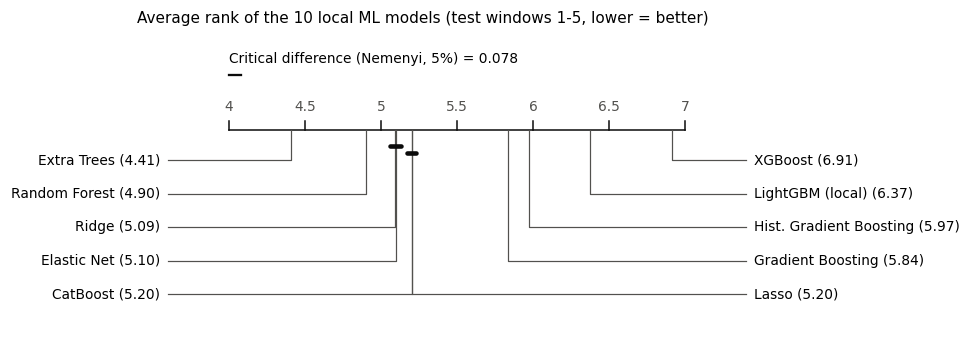

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_1_critical_difference.png
(Not plotted: oracle, best ML model per product = 0.7102; it would squeeze the scale.)


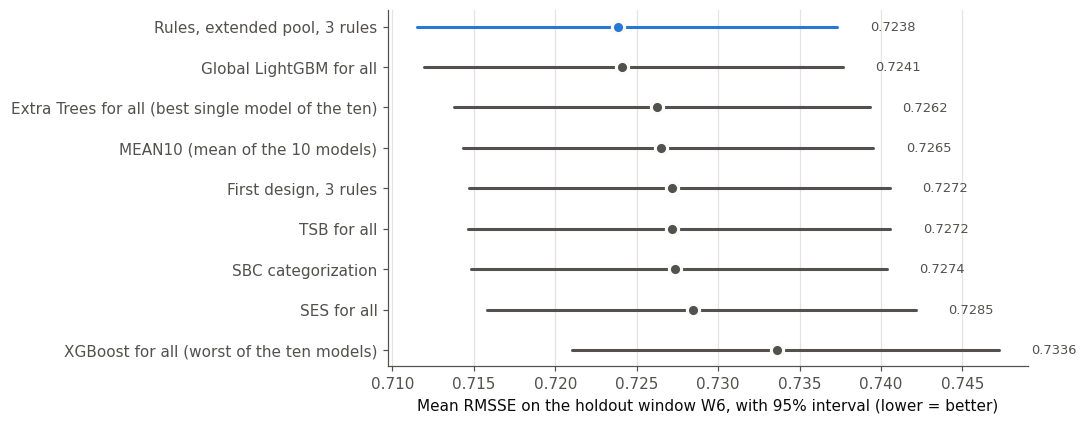

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_2_holdout_rmsse.png


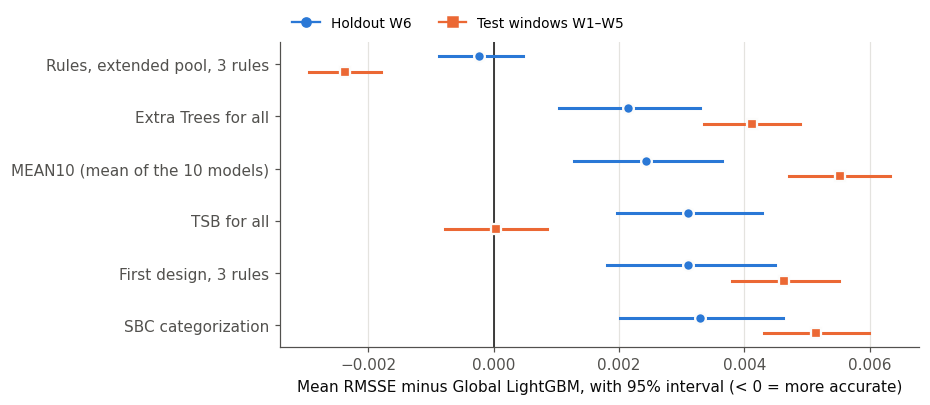

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_3_paired_vs_global.png


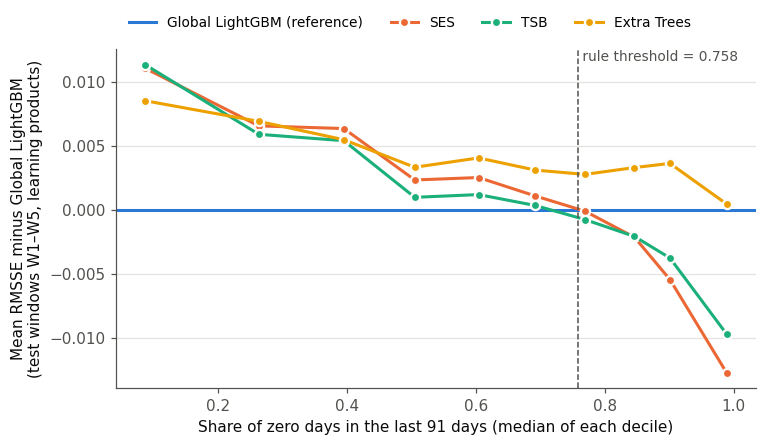

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_4_rule_mechanism.png


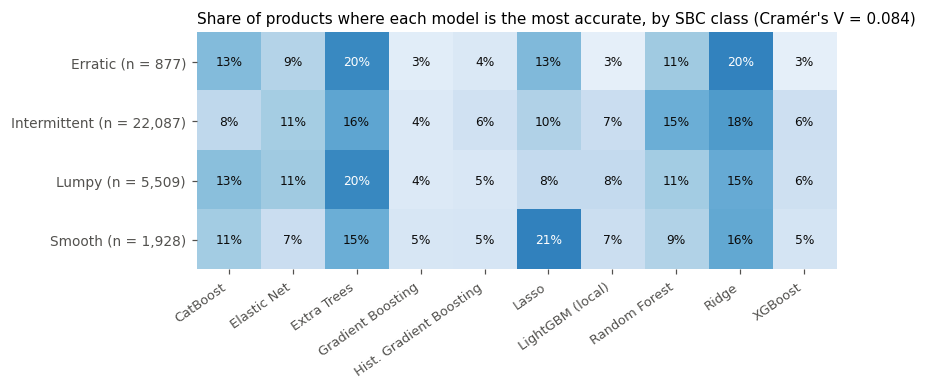

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_5_sbc_vs_best_model.png
✅ 5 figures saved in /content/drive/MyDrive/M5_Thesis/results/v2/final/figures


In [ ]:
# Cell 14 — Figures for Chapter 4 (about 2-5 minutes). Needs Cells 1-9 and 12 in this session.
# Saved as PNG (300 dpi, for Word) and PDF (vector) in results/v2/final/figures/.
import matplotlib.pyplot as plt
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
INK, INK2, GRID, BLUE, ORANGE, AQUA, YELLOW = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.bbox': 'tight'})
NICE = {'EXTRA_TREES': 'Extra Trees', 'RANDOM_FOREST': 'Random Forest', 'RIDGE': 'Ridge', 'LASSO': 'Lasso', 'ELASTIC_NET': 'Elastic Net',
        'CATBOOST': 'CatBoost', 'LGBM': 'LightGBM (local)', 'XGBOOST': 'XGBoost', 'HGBR': 'Hist. Gradient Boosting',
        'GRADIENT_BOOST': 'Gradient Boosting', 'GLOBAL_LGBM': 'Global LightGBM', 'SES': 'SES', 'TSB': 'TSB', 'MEAN10': 'Mean of 10 ML models'}
nice = lambda m: NICE.get(m, m)
def save(fig, name):
    for ext in ('png', 'pdf'): fig.savefig(f'{FIG}/{name}.{ext}', dpi=300)
    plt.show(); print('saved', f'{FIG}/{name}.png')

# Figure 4.1 — Critical-difference diagram, 10 ML models (Friedman-Nemenyi, Cell 7)
rk = M10.rank(axis=1).mean().sort_values(); n = len(rk)
lo, hi = np.floor(rk.min() * 2) / 2, np.ceil(rk.max() * 2) / 2
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.set_xlim(lo - 0.6, hi + 0.6); ax.set_ylim(-(n + 1) // 2 * 0.55 - 0.1, 1.6); ax.axis('off')
ax.plot([lo, hi], [0, 0], color=INK, lw=1)
for t in np.arange(lo, hi + 1e-9, 0.5):
    ax.plot([t, t], [0, 0.15], color=INK, lw=1); ax.text(t, 0.3, f'{t:g}', ha='center', fontsize=9, color=INK2)
ax.plot([lo, lo + cd], [0.9, 0.9], color=INK, lw=1.5); ax.text(lo, 1.05, f'Critical difference (Nemenyi, 5%) = {cd:.3f}', ha='left', va='bottom', fontsize=9)
half = (n + 1) // 2
for i, (m, r) in enumerate(rk.items()):
    left = i < half; y = -(i if left else n - 1 - i) * 0.55 - 0.5
    xe = lo - 0.4 if left else hi + 0.4
    ax.plot([r, r, xe], [0, y, y], color=INK2, lw=0.8)
    ax.text(xe + (-0.05 if left else 0.05), y, f'{nice(m)} ({r:.2f})', ha='right' if left else 'left', va='center', fontsize=9)
groups, vals = [], rk.values                                  # maximal groups of models not significantly different
for i in range(n):
    j = max(k for k in range(i, n) if vals[k] - vals[i] <= cd)
    if j > i and not any(a <= i and j <= b for a, b in groups): groups.append((i, j))
for g, (i, j) in enumerate(groups):
    yy = -0.15 - 0.12 * (g + 1); ax.plot([vals[i] - 0.03, vals[j] + 0.03], [yy, yy], color=INK, lw=3, solid_capstyle='round')
ax.set_title('Average rank of the 10 local ML models (test windows 1-5, lower = better)', fontsize=10, loc='left')
save(fig, 'fig4_1_critical_difference')

# Figure 4.2 — Holdout mean RMSSE with 95% CI on the test products
EXT3 = 'RMSSE-rules, Extended pool, 3 rules'
show = [(EXT3, 'Rules, extended pool, 3 rules'),
        ('GLOBAL_LGBM', 'Global LightGBM for all'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all (best single model of the ten)"),
        ('MEAN10', 'MEAN10 (mean of the 10 models)'), ('TSB', 'TSB for all'), ('SES', 'SES for all'),
        ('New categorization (CART, 3 rules)', 'First design, 3 rules'),
        ('SBC categorization', 'SBC categorization'), ('XGBOOST for all', 'XGBoost for all (worst of the ten models)')]
st = []
for k, lab in show:
    s = summary(VALS[k][0], best_h); st.append((lab, s['Mean RMSSE'], s['CI 2.5%'], s['CI 97.5%'], k))
st = sorted(st, key=lambda z: -z[1])
fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
for i, (lab, m, a, b, k) in enumerate(st):
    c = BLUE if k == EXT3 else INK2
    ax.plot([a, b], [i, i], color=c, lw=2, solid_capstyle='round'); ax.plot(m, i, 'o', ms=8, color=c, mec='#fcfcfb', mew=2)
    ax.text(b + 0.002, i, f'{m:.4f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(range(len(st))); ax.set_yticklabels([z[0] for z in st]); ax.set_xlabel('Mean RMSSE on the holdout window W6, with 95% interval (lower = better)')
print(f'(Not plotted: oracle, best ML model per product = {np.average(best_h, weights=W):.4f}; it would squeeze the scale.)')
save(fig, 'fig4_2_holdout_rmsse')

# Figure 4.3 — Paired differences against Global LightGBM (holdout and test windows)
cmp = [(EXT3, 'Rules, extended pool, 3 rules'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all"), ('MEAN10', 'MEAN10 (mean of the 10 models)'),
       ('TSB', 'TSB for all'), ('New categorization (CART, 3 rules)', 'First design, 3 rules'), ('SBC categorization', 'SBC categorization')]
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True); ax.axvline(0, color=INK, lw=1)
for i, (k, lab) in enumerate(cmp[::-1]):
    for w, off, c, mk in [(0, 0.15, BLUE, 'o'), (1, -0.15, ORANGE, 's')]:
        p = paired(k, 'GLOBAL_LGBM', w)
        ax.plot([p['CI 2.5%'], p['CI 97.5%']], [i + off] * 2, color=c, lw=2); ax.plot(p['Difference in mean RMSSE'], i + off, mk, ms=7, color=c, mec='#fcfcfb', mew=1.5)
ax.set_yticks(range(len(cmp))); ax.set_yticklabels([z[1] for z in cmp[::-1]])
ax.plot([], [], 'o-', color=BLUE, label='Holdout W6'); ax.plot([], [], 's-', color=ORANGE, label='Test windows W1–W5')
ax.legend(frameon=False, fontsize=9, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_xlabel('Mean RMSSE minus Global LightGBM, with 95% interval (< 0 = more accurate)')
save(fig, 'fig4_3_paired_vs_global')

# Figure 4.4 — Why the rule works: RMSSE minus Global LightGBM, by share of zero-sales days in the last 91 days
# (learning products, test windows 1-5; < 0 = the method is more accurate than Global LightGBM in that decile)
t3 = CORR[EXT3]; f0, thr = t3['splits'][0][1]; feat_name = SCALE_FREE[f0]
z = X.loc[TRAIN, feat_name]; bins = np.unique(np.quantile(z, np.linspace(0, 1, 11)))
grp = pd.cut(z, bins, include_lowest=True)
lines = [('SES', ORANGE), ('TSB', AQUA), (L90['best_single'], YELLOW)]
A5 = ALL5.reindex(d.index)[TRAIN]
tab = A5[[m for m, _ in lines]].sub(A5['GLOBAL_LGBM'], axis=0).groupby(grp.values, observed=True).mean()
mid = z.groupby(grp.values, observed=True).median().values
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axhline(0, color=BLUE, lw=2, label='Global LightGBM (reference)')
for m, c in lines:
    ax.plot(mid, tab[m].values, '-o', color=c, lw=2, ms=6, mec='#fcfcfb', mew=1.5, label=nice(m))
ax.axvline(thr, color=INK2, lw=1, ls='--'); ax.text(thr, ax.get_ylim()[1], f' rule threshold = {thr:.3f}', va='top', fontsize=9, color=INK2)
ax.set_xlabel('Share of zero days in the last 91 days (median of each decile)')
ax.set_ylabel('Mean RMSSE minus Global LightGBM\n(test windows W1–W5, learning products)')
ax.legend(frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.02))
save(fig, 'fig4_4_rule_mechanism')

# Figure 4.5 — SBC class vs best ML model (row shares, all products; RQ2)
sh = ct.div(ct.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(7.5, 2.8)); im = ax.imshow(sh.values, cmap='Blues', vmin=0, vmax=max(0.3, sh.values.max()), aspect='auto')
ax.set_xticks(range(sh.shape[1])); ax.set_xticklabels([nice(c) for c in sh.columns], rotation=35, ha='right', fontsize=8.5)
ax.set_yticks(range(sh.shape[0])); ax.set_yticklabels([f'{c.title()} (n = {ct.loc[c].sum():,})' for c in sh.index], fontsize=9)
for i in range(sh.shape[0]):
    for j in range(sh.shape[1]):
        v = sh.values[i, j]; ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * im.get_clim()[1] else INK)
ax.spines[:].set_visible(False); ax.set_title(f"Share of products where each model is the most accurate, by SBC class (Cramér's V = {V:.3f})", fontsize=10, loc='left')
save(fig, 'fig4_5_sbc_vs_best_model')
print('✅ 5 figures saved in', FIG)

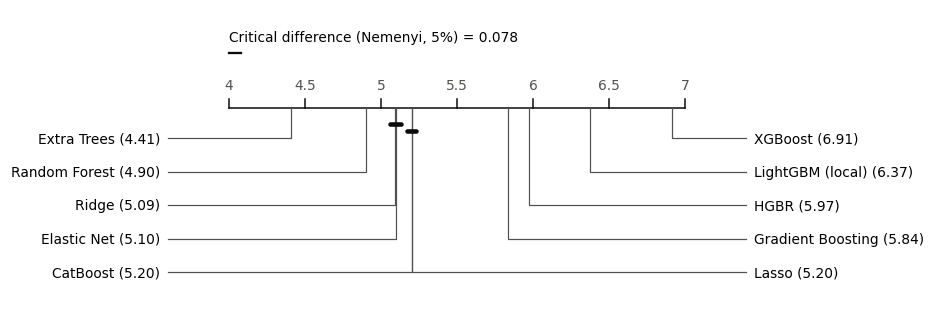

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_1_critical_difference.png
(Not plotted: oracle, best ML model per product = 0.7102; it would squeeze the scale.)


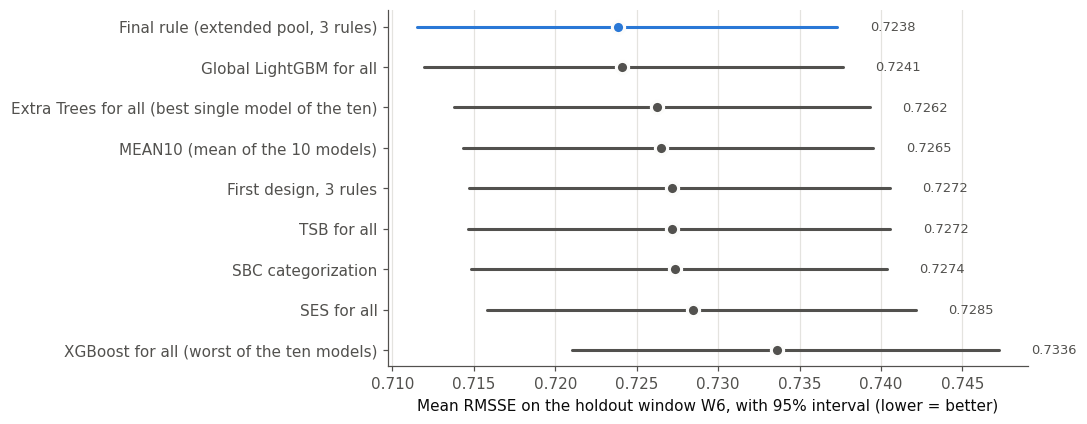

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_2_holdout_rmsse.png


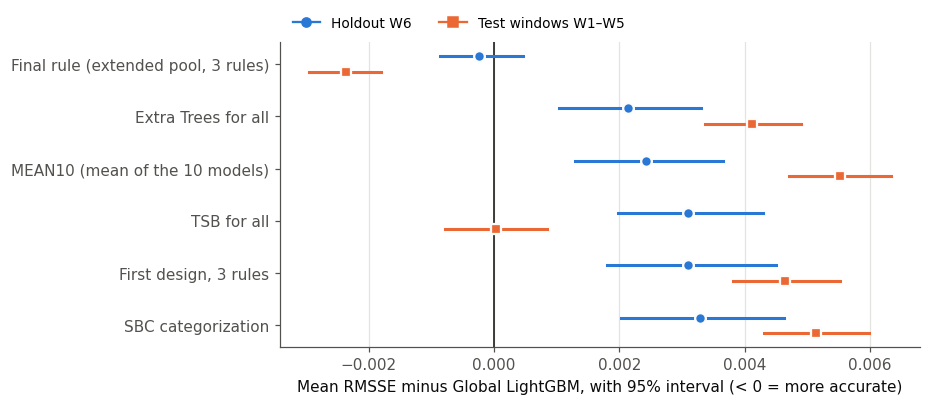

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_3_paired_vs_global.png


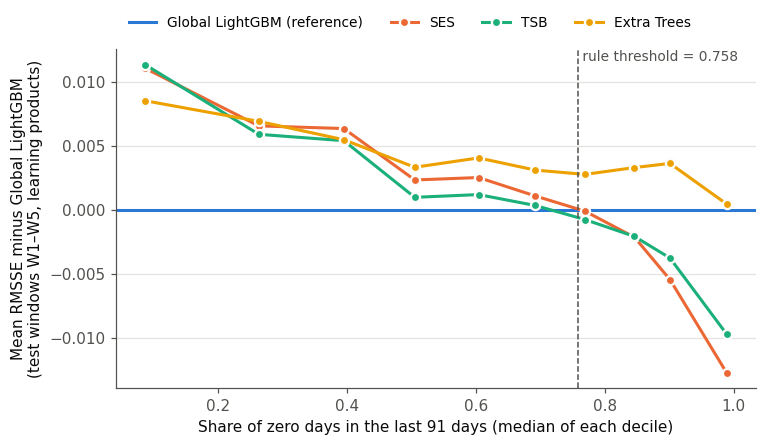

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_4_rule_mechanism.png


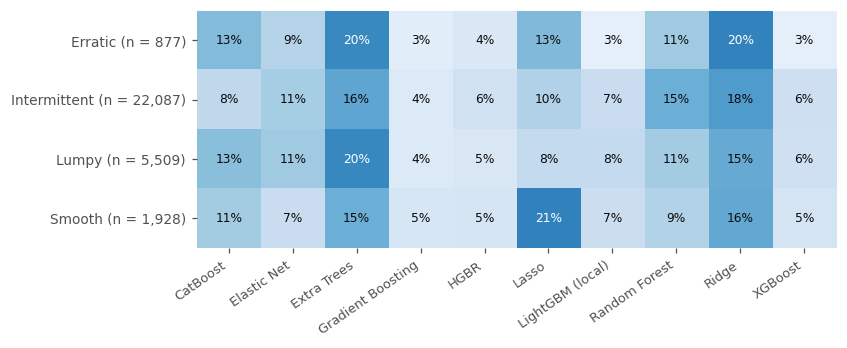

saved /content/drive/MyDrive/M5_Thesis/results/v2/final/figures/fig4_5_sbc_vs_best_model.png
✅ 5 figures saved in /content/drive/MyDrive/M5_Thesis/results/v2/final/figures


In [ ]:
# Cell 14 — Figures for Chapter 4 (about 2-5 minutes). Needs Cells 1-9 and 12 in this session.
# Saved as PNG (300 dpi, for Word) and PDF (vector) in results/v2/final/figures/.
import matplotlib.pyplot as plt
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
INK, INK2, GRID, BLUE, ORANGE, AQUA, YELLOW = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.bbox': 'tight'})
NICE = {'EXTRA_TREES': 'Extra Trees', 'RANDOM_FOREST': 'Random Forest', 'RIDGE': 'Ridge', 'LASSO': 'Lasso', 'ELASTIC_NET': 'Elastic Net',
        'CATBOOST': 'CatBoost', 'LGBM': 'LightGBM (local)', 'XGBOOST': 'XGBoost', 'HGBR': 'HGBR',
        'GRADIENT_BOOST': 'Gradient Boosting', 'GLOBAL_LGBM': 'Global LightGBM', 'SES': 'SES', 'TSB': 'TSB', 'MEAN10': 'Mean of 10 ML models'}
nice = lambda m: NICE.get(m, m)
def save(fig, name):
    for ext in ('png', 'pdf'): fig.savefig(f'{FIG}/{name}.{ext}', dpi=300)
    plt.show(); print('saved', f'{FIG}/{name}.png')

# Figure 4.1 — Critical-difference diagram, 10 ML models (Friedman-Nemenyi, Cell 7)
rk = M10.rank(axis=1).mean().sort_values(); n = len(rk)
lo, hi = np.floor(rk.min() * 2) / 2, np.ceil(rk.max() * 2) / 2
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.set_xlim(lo - 0.6, hi + 0.6); ax.set_ylim(-(n + 1) // 2 * 0.55 - 0.1, 1.6); ax.axis('off')
ax.plot([lo, hi], [0, 0], color=INK, lw=1)
for t in np.arange(lo, hi + 1e-9, 0.5):
    ax.plot([t, t], [0, 0.15], color=INK, lw=1); ax.text(t, 0.3, f'{t:g}', ha='center', fontsize=9, color=INK2)
ax.plot([lo, lo + cd], [0.9, 0.9], color=INK, lw=1.5); ax.text(lo, 1.05, f'Critical difference (Nemenyi, 5%) = {cd:.3f}', ha='left', va='bottom', fontsize=9)
half = (n + 1) // 2
for i, (m, r) in enumerate(rk.items()):
    left = i < half; y = -(i if left else n - 1 - i) * 0.55 - 0.5
    xe = lo - 0.4 if left else hi + 0.4
    ax.plot([r, r, xe], [0, y, y], color=INK2, lw=0.8)
    ax.text(xe + (-0.05 if left else 0.05), y, f'{nice(m)} ({r:.2f})', ha='right' if left else 'left', va='center', fontsize=9)
groups, vals = [], rk.values                                  # maximal groups of models not significantly different
for i in range(n):
    j = max(k for k in range(i, n) if vals[k] - vals[i] <= cd)
    if j > i and not any(a <= i and j <= b for a, b in groups): groups.append((i, j))
for g, (i, j) in enumerate(groups):
    yy = -0.15 - 0.12 * (g + 1); ax.plot([vals[i] - 0.03, vals[j] + 0.03], [yy, yy], color=INK, lw=3, solid_capstyle='round')
save(fig, 'fig4_1_critical_difference')

# Figure 4.2 — Holdout mean RMSSE with 95% CI on the test products
EXT3 = 'RMSSE-rules, Extended pool, 3 rules'
show = [(EXT3, 'Final rule (extended pool, 3 rules)'),
        ('GLOBAL_LGBM', 'Global LightGBM for all'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all (best single model of the ten)"),
        ('MEAN10', 'MEAN10 (mean of the 10 models)'), ('TSB', 'TSB for all'), ('SES', 'SES for all'),
        ('New categorization (CART, 3 rules)', 'First design, 3 rules'),
        ('SBC categorization', 'SBC categorization'), ('XGBOOST for all', 'XGBoost for all (worst of the ten models)')]
st = []
for k, lab in show:
    s = summary(VALS[k][0], best_h); st.append((lab, s['Mean RMSSE'], s['CI 2.5%'], s['CI 97.5%'], k))
st = sorted(st, key=lambda z: -z[1])
fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
for i, (lab, m, a, b, k) in enumerate(st):
    c = BLUE if k == EXT3 else INK2
    ax.plot([a, b], [i, i], color=c, lw=2, solid_capstyle='round'); ax.plot(m, i, 'o', ms=8, color=c, mec='#fcfcfb', mew=2)
    ax.text(b + 0.002, i, f'{m:.4f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(range(len(st))); ax.set_yticklabels([z[0] for z in st]); ax.set_xlabel('Mean RMSSE on the holdout window W6, with 95% interval (lower = better)')
print(f'(Not plotted: oracle, best ML model per product = {np.average(best_h, weights=W):.4f}; it would squeeze the scale.)')
save(fig, 'fig4_2_holdout_rmsse')

# Figure 4.3 — Paired differences against Global LightGBM (holdout and test windows)
cmp = [(EXT3, 'Final rule (extended pool, 3 rules)'), ('Best single model (learned)', f"{nice(L90['best_single'])} for all"), ('MEAN10', 'MEAN10 (mean of the 10 models)'),
       ('TSB', 'TSB for all'), ('New categorization (CART, 3 rules)', 'First design, 3 rules'), ('SBC categorization', 'SBC categorization')]
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True); ax.axvline(0, color=INK, lw=1)
for i, (k, lab) in enumerate(cmp[::-1]):
    for w, off, c, mk in [(0, 0.15, BLUE, 'o'), (1, -0.15, ORANGE, 's')]:
        p = paired(k, 'GLOBAL_LGBM', w)
        ax.plot([p['CI 2.5%'], p['CI 97.5%']], [i + off] * 2, color=c, lw=2); ax.plot(p['Difference in mean RMSSE'], i + off, mk, ms=7, color=c, mec='#fcfcfb', mew=1.5)
ax.set_yticks(range(len(cmp))); ax.set_yticklabels([z[1] for z in cmp[::-1]])
ax.plot([], [], 'o-', color=BLUE, label='Holdout W6'); ax.plot([], [], 's-', color=ORANGE, label='Test windows W1–W5')
ax.legend(frameon=False, fontsize=9, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_xlabel('Mean RMSSE minus Global LightGBM, with 95% interval (< 0 = more accurate)')
save(fig, 'fig4_3_paired_vs_global')

# Figure 4.4 — Why the rule works: RMSSE minus Global LightGBM, by share of zero-sales days in the last 91 days
# (learning products, test windows 1-5; < 0 = the method is more accurate than Global LightGBM in that decile)
t3 = CORR[EXT3]; f0, thr = t3['splits'][0][1]; feat_name = SCALE_FREE[f0]
z = X.loc[TRAIN, feat_name]; bins = np.unique(np.quantile(z, np.linspace(0, 1, 11)))
grp = pd.cut(z, bins, include_lowest=True)
lines = [('SES', ORANGE), ('TSB', AQUA), (L90['best_single'], YELLOW)]
A5 = ALL5.reindex(d.index)[TRAIN]
tab = A5[[m for m, _ in lines]].sub(A5['GLOBAL_LGBM'], axis=0).groupby(grp.values, observed=True).mean()
mid = z.groupby(grp.values, observed=True).median().values
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axhline(0, color=BLUE, lw=2, label='Global LightGBM (reference)')
for m, c in lines:
    ax.plot(mid, tab[m].values, '-o', color=c, lw=2, ms=6, mec='#fcfcfb', mew=1.5, label=nice(m))
ax.axvline(thr, color=INK2, lw=1, ls='--'); ax.text(thr, ax.get_ylim()[1], f' rule threshold = {thr:.3f}', va='top', fontsize=9, color=INK2)
ax.set_xlabel('Share of zero days in the last 91 days (median of each decile)')
ax.set_ylabel('Mean RMSSE minus Global LightGBM\n(test windows W1–W5, learning products)')
ax.legend(frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.02))
save(fig, 'fig4_4_rule_mechanism')

# Figure 4.5 — SBC class vs best ML model (row shares, all products; RQ2)
sh = ct.div(ct.sum(1), axis=0)
sh = sh.reindex([c for c in ['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC'] if c in sh.index])
fig, ax = plt.subplots(figsize=(7.5, 2.8)); im = ax.imshow(sh.values, cmap='Blues', vmin=0, vmax=max(0.3, sh.values.max()), aspect='auto')
ax.set_xticks(range(sh.shape[1])); ax.set_xticklabels([nice(c) for c in sh.columns], rotation=35, ha='right', fontsize=8.5)
ax.set_yticks(range(sh.shape[0])); ax.set_yticklabels([f'{c.title()} (n = {ct.loc[c].sum():,})' for c in sh.index], fontsize=9)
for i in range(sh.shape[0]):
    for j in range(sh.shape[1]):
        v = sh.values[i, j]; ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * im.get_clim()[1] else INK)
ax.spines[:].set_visible(False)
save(fig, 'fig4_5_sbc_vs_best_model')
print('✅ 5 figures saved in', FIG)

In [1]:
# Cell 21 — Validation of the 3,305-product sample (tests T1–T6, Section 3.6.4)
# T1, T2, T3 and T5 repeat the original tests exactly (reference classes, days 1–1,913,
# mean sales = mean daily sales on the days with a sale). T4 and T6 are now measured
# with the population weights of Section 3.6.5. Result file: Sample_validation_v2.xlsx
import numpy as np, pandas as pd
from scipy import stats
try:
    from google.colab import drive
    drive.mount('/content/drive')
    D = '/content/drive/MyDrive/M5_Thesis'
except ImportError:
    D = LOCAL_D

sales = pd.read_csv(f'{D}/data/sales_train_validation.csv')
day_cols = [c for c in sales.columns if c.startswith('d_')]
assert len(day_cols) == 1913, f'expected 1,913 days, found {len(day_cols)}'
ref = pd.read_csv(f'{D}/results/demand_classification_results.csv')       # reference classes (days 1–1,913)
smp = pd.read_csv(f'{D}/results/FINAL_SAMPLE_3305.csv')                    # the 3,305 sample products
assert len(smp) == 3305

Y = sales.set_index('id').loc[ref['id'], day_cols].values.astype(float)    # rows aligned with ref
row = {i: k for k, i in enumerate(ref['id'])}
CLASSES = ['INTERMITTENT', 'LUMPY', 'SMOOTH', 'ERRATIC']
ALLOC = {'INTERMITTENT': 2345, 'LUMPY': 600, 'SMOOTH': 250, 'ERRATIC': 110}
THR = {'INTERMITTENT': (8, 95), 'LUMPY': (9, 95), 'SMOOTH': (10, 90), 'ERRATIC': (10, 90)}

def nz_mean(rows, cols=slice(None)):
    v = Y[rows][:, cols]; return v[v > 0].mean()

out = []
for c in CLASSES:
    av = ref[ref['demand_category'] == c].reset_index(drop=True)
    n = ALLOC[c]
    # T1 — stability of the class mean of MDI over 200 draws
    boot = [av.sample(n=n, random_state=s)['MDI'].mean() for s in range(200)]
    t1 = 100 * np.std(boot) / np.mean(boot)
    # T2 — KS test on MDI, share of 100 draws with p > 0.05
    t2 = sum(stats.ks_2samp(av['MDI'].dropna(), av.sample(n=n, random_state=s)['MDI'].dropna())[1] > 0.05
             for s in range(100))
    # T3 — mean sales on days with a sale, share of 100 draws within the class's precision limit
    pop_rows = [row[i] for i in av['id']]; pm = nz_mean(pop_rows)
    dev, need = THR[c]
    t3 = sum(100 * abs(pm - nz_mean([row[i] for i in av.sample(n=n, random_state=s)['id']])) / pm < dev
             for s in range(100))
    out.append({'Class': c, 'n': n, 'T1 CV% of class mean MDI': round(t1, 2), 'T1 pass (<5%)': t1 < 5,
                'T2 % draws KS p>0.05': t2, 'T2 pass (>=95)': t2 >= 95,
                'T3 % draws within limit': t3, 'T3 limit': f'{dev}% in {need}% of draws', 'T3 pass': t3 >= need})
per_class = pd.DataFrame(out)
print(per_class.to_string(index=False))

# Weights of Section 3.6.5: population share / sample share of the reference class
cls = smp.set_index('id')['demand_category']
pop_share = ref['demand_category'].value_counts(normalize=True)
smp_share = cls.value_counts(normalize=True)
w_class = (pop_share / smp_share).to_dict()
s_rows = np.array([row[i] for i in smp['id']])
w = np.array([w_class[cls[i]] for i in smp['id']])
all_rows = np.arange(len(ref))

def w_stats(rows, wts, cols=slice(None)):
    v = Y[rows][:, cols]; pos = v > 0
    mean_nz = (v * wts[:, None]).sum() / (pos * wts[:, None]).sum()
    zero = ((~pos) * wts[:, None]).sum() / (wts.sum() * v.shape[1])
    return mean_nz, zero

ones = np.ones(len(all_rows))
p_mean, p_zero = w_stats(all_rows, ones)
rows4 = []
for label, wts in [('unweighted', np.ones(len(w))), ('weighted (Section 3.6.5)', w)]:
    s_mean, s_zero = w_stats(s_rows, wts)
    # KS on MDI with the weighted empirical distribution of the sample and Kish's effective size
    pop_m = np.sort(ref['MDI'].dropna().values); o = np.argsort(smp['MDI'].values)
    xs, cw = smp['MDI'].values[o], np.cumsum(wts[o]) / wts.sum()
    grid = np.union1d(pop_m, xs); k = np.searchsorted(xs, grid, side='right')
    F_s = np.where(k > 0, cw[np.maximum(k - 1, 0)], 0.0)
    F_p = np.searchsorted(pop_m, grid, side='right') / len(pop_m)
    D_ks = np.abs(F_p - F_s).max(); n_eff = wts.sum() ** 2 / (wts ** 2).sum()
    ks_p = stats.kstwo.sf(D_ks, int(round(n_eff * len(pop_m) / (n_eff + len(pop_m)))))
    md, zd = 100 * abs(s_mean - p_mean) / p_mean, 100 * abs(s_zero - p_zero)
    rows4.append({'Sample': label, 'Mean sales diff %': round(md, 2), 'Zero-rate diff (points)': round(zd, 2),
                  'KS p on MDI': round(ks_p, 4), 'T4 pass': md < 5 and zd < 5 and ks_p > 0.05})
t4 = pd.DataFrame(rows4); print('\nT4 — combined sample'); print(t4.to_string(index=False))

st = smp['id'].str.extract(r'_(CA_\d|TX_\d|WI_\d)_')[0]; dp = smp['id'].str.extract(r'^(FOODS_\d|HOBBIES_\d|HOUSEHOLD_\d)')[0]
t5 = pd.DataFrame([{'Stores covered': st.nunique(), 'Departments covered': dp.nunique(),
                    'Largest store share %': round(100 * st.value_counts(normalize=True).max(), 2),
                    'T5 pass (10/10, 7/7, <25%)': st.nunique() == 10 and dp.nunique() == 7
                    and st.value_counts(normalize=True).max() < 0.25}])
print('\nT5 — stores and departments'); print(t5.to_string(index=False))

thirds = [(0, 637, 'days 1–637'), (637, 1275, 'days 638–1,275'), (1275, 1913, 'days 1,276–1,913')]
rows6 = []
for a, b, lab in thirds:
    pm6, _ = w_stats(all_rows, ones, slice(a, b))
    for label, wts in [('unweighted', np.ones(len(w))), ('weighted', w)]:
        sm6, _ = w_stats(s_rows, wts, slice(a, b))
        d6 = 100 * abs(sm6 - pm6) / pm6
        rows6.append({'Period': lab, 'Sample': label, 'Population mean': round(pm6, 4),
                      'Sample mean': round(sm6, 4), 'Diff %': round(d6, 2), 'Pass (<5%)': d6 < 5})
t6 = pd.DataFrame(rows6); print('\nT6 — three periods'); print(t6.to_string(index=False))

with pd.ExcelWriter(f'{D}/results/Sample_validation_v2.xlsx') as xw:
    per_class.to_excel(xw, sheet_name='T1-T3 per class', index=False)
    t4.to_excel(xw, sheet_name='T4 combined', index=False)
    t5.to_excel(xw, sheet_name='T5 stores', index=False)
    t6.to_excel(xw, sheet_name='T6 periods', index=False)
print(f'\n✅ Saved: {D}/results/Sample_validation_v2.xlsx')

Mounted at /content/drive
       Class    n  T1 CV% of class mean MDI  T1 pass (<5%)  T2 % draws KS p>0.05  T2 pass (>=95)  T3 % draws within limit            T3 limit  T3 pass
INTERMITTENT 2345                      2.33           True                    98            True                       95  8% in 95% of draws     True
       LUMPY  600                      4.97           True                    97            True                       95  9% in 95% of draws     True
      SMOOTH  250                      0.44           True                    99            True                       92 10% in 90% of draws     True
     ERRATIC  110                      0.49           True                   100            True                       90 10% in 90% of draws     True

T4 — combined sample
                  Sample  Mean sales diff %  Zero-rate diff (points)  KS p on MDI  T4 pass
              unweighted              20.11                     3.49       0.0000    False
weighted (Secti

In [2]:
   import shutil
   shutil.copy(f'{D}/results/Sample_validation_v2.xlsx', f'{D}/results/v2/final/Sample_validation_v2.xlsx')
   print('✅ Copied to results/v2/final')

✅ Copied to results/v2/final


In [3]:
# Read-only check of the evaluation results (Cell 5 counts). Writes nothing.
import glob, pandas as pd
D = '/content/drive/MyDrive/M5_Thesis'
EV = f'{D}/results/v2/eval'
files = sorted(glob.glob(f'{EV}/rmsse_*.csv'))
print('Result chunks found:', len(files))
R = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print('Status counts:', R['Status'].value_counts().to_dict())
ok = R[R['Status'] == 'ok']
full = ok.groupby(['SKU_ID', 'Window'])['Model'].transform('size') == 10
removed = ok.loc[~full, ['SKU_ID', 'Window']].drop_duplicates()
print('Windows removed because not all 10 models succeeded:', len(removed))
print(removed.to_string(index=False))
err = R[R['Status'].astype(str).str.startswith('error')]
print('Products where a model failed in at least one window:', err['SKU_ID'].nunique())
print(err[['SKU_ID', 'Window', 'Model', 'Status']].head(20).to_string(index=False))
print('\nFOODS_2_107_TX_3 rows by window and status:')
print(R[R['SKU_ID'].str.startswith('FOODS_2_107_TX_3')].groupby(['Window', 'Status']).size().to_string())

Result chunks found: 122
Status counts: {'ok': 1827150, 'skipped: history too short or constant': 225}
Windows removed because not all 10 models succeeded: 0
Empty DataFrame
Columns: [SKU_ID, Window]
Index: []
Products where a model failed in at least one window: 0
Empty DataFrame
Columns: [SKU_ID, Window, Model, Status]
Index: []

FOODS_2_107_TX_3 rows by window and status:
Window  Status                                
1       skipped: history too short or constant     1
2       skipped: history too short or constant     1
3       ok                                        10
4       ok                                        10
5       ok                                        10
6       ok                                        10
